# Dimers of plasmonic rods: quadrupoles, and bianisotropy as first-order spatial dispersion

The magnetic atom of most optical metamaterials is a pair of metal strips (the cut-wire pair, the building block of fishnet structures): the antisymmetric mode, in which the two strips carry opposite currents, has a magnetic moment. It also has an electric quadrupole moment, and it has been argued that the "magnetic" response of such pairs cannot be separated from the quadrupole one. In the language of this folder the question is sharp. With $\mathbf E$ in the plane there is exactly one magnetic second-order coefficient, $\mu_{zz}$, whatever the symmetry (notebook 01, section 3), so a dimer that responds magnetically to waves along one axis and hardly at all to waves along the other is showing second-order terms that are not a permeability. And a dimer whose two members differ has no inversion symmetry, so terms of *first* order in $\mathbf k$ appear, which notebook 01 identified with magnetoelectric (bianisotropic) coupling. This notebook computes both effects exactly for a square lattice whose unit cell holds two Drude-metal rods.

## What this notebook shows

- A symmetry count, by group averaging, for the point groups of the two dimers: the second-order TE coefficients (five for both, of which one is magnetic) and the first-order ones allowed by reciprocity (none for the symmetric dimer, one for the dimer with unequal rods). Transverse waves see only the angular dependence $c_T(\varphi)=\tau+a_2\cos2\varphi+a_4\cos4\varphi$ of the second-order response, and only $\tau$ can contain the magnetic part.
- The isolated dimer (a molecule $T$-matrix): the mode in which the two rods carry opposite currents, its frequency, its radiated multipole content (magnetic dipole $m=0$ against the quadrupole orders $m=\pm2$), a field snapshot, and a reciprocity check between how it radiates and how it is excited.
- The lattice of symmetric dimers: all five second-order coefficients through the resonances, the apparent permeabilities for propagation along the dimer axis ($\mu_X$) and across it ($\mu_Y$), and what part of the antisymmetric resonance each of them sees.
- The dimer with unequal rods: the first-order coefficient that the mirror symmetry allows, its resonance, its dependence on the difference of the radii, which magnetoelectric coupling it is, and what it does and does not do to bulk waves.

## Conventions

Time dependence $e^{-i\omega t}$, outgoing cylindrical waves $H_l^{(1)}$, $\varepsilon_0=\mu_0=c=1$ so that $\omega=k_0$, lengths in units of the lattice period $a=1$. The frequency is $f=a/\lambda_0=k_0/2\pi$, and the symbol $f$ means nothing else. TE means $\mathbf H$ along the rods ($z$); all wave vectors lie in the $x$-$y$ plane. $\varepsilon(\omega,\mathbf k)$ is the single Landau-Lifshitz tensor of notebook 01: the exponential $e^{i\mathbf k\cdot\mathbf r}$ components of the fields averaged over a cell, with all induced current in the tensor. The rods are Drude metal, $\varepsilon_m=1-f_p^2/[f(f+if_\gamma)]$, with $f_p=a/\lambda_p$ the plasma frequency. The cell has period 1 and holds two rods of radii $r_1,r_2$ centered at $(-(r_1+g/2),0)$ and $(r_2+g/2,0)$ with a gap $g$; the dimer axis is $x$. The solver is `basislattice.py` (several rods per cell, validated against plane waves in the folder's scratch checks) on top of `rodlattice.py`.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/spatial_dispersion (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # rodlattice.py and basislattice.py sit next to this notebook
import rodlattice as rl
import basislattice as bl
from scipy.special import jv, jvp, yv, yvp, hankel1
from scipy.optimize import brentq, minimize_scalar
from scipy.signal import find_peaks

TWO_PI = 2 * np.pi
rng = np.random.default_rng(9)
T_START = time.time()

## 0. The structure

**Choice of parameters.** A thin rod of Drude metal has its dipole resonance (for $\mathbf H$ along the rod) near $\varepsilon_m=-1$, that is $f=f_p/\sqrt2$. The choice is $f_p=0.25$, so that the plasmon resonances of the pair fall at $a/\lambda_0$ between 0.13 and 0.18, deep below the first diffraction threshold ($a/\lambda_0=1$) and in the range that notebook 08 uses for rings. The pair is made of rods of radius $r=0.15$ with a gap $g=0.06$. The suggested start of $r=0.1$, $g=0.04$ has nearly the same frequencies (for an isolated pair in the quasi-static limit the resonances depend on $g/r$ and not on the size; the lattice shifts them a little, the printed table in section 3 shows by how much) but a much weaker response: the last cell of section 3 prints the residue of the antisymmetric pole at fixed $g/r$ for $r=0.10$ and $r=0.15$ (about four times larger for the larger pair), and this is why $r=0.15$ is used. (It also prints $r=0.20$, where the comparison is not like for like; see there.) The loss is $f_\gamma=f_p/300$ (bulk-silver) when it is on, and zero otherwise ("collisionless").

In [3]:
FP = 0.25            # plasma frequency a / lambda_p
R0, GAP = 0.15, 0.06 # radius of each rod and gap of the symmetric dimer
FG = FP / 300        # f_gamma of the bulk-silver case


def drude(f, fg=0.0):
    """Drude permittivity; a real float when there is no loss."""
    e = 1 - FP**2 / (f * (f + 1j * fg))
    return float(e.real) if fg == 0 else complex(e)


def dimer(r1, r2, gap, eps):
    """Two rods on the x axis, centered at -(r1 + gap/2) and r2 + gap/2."""
    return [bl.Rod((-(r1 + gap / 2), 0.0), r1, eps), bl.Rod((r2 + gap / 2, 0.0), r2, eps)]


rods0 = dimer(R0, R0, GAP, drude(0.15))
gap_min = bl.check_rods(rods0)
print(f"centers {[tuple(np.round(r.d, 3)) for r in rods0]}, radius {R0}, gap {GAP}; smallest gap to a rod or its image: {gap_min:.4f}")
print(f"filling fraction of the two rods, 2 pi r^2 = {2 * np.pi * R0**2:.3f}; single-rod dipole resonance f_p/sqrt(2) = {FP / np.sqrt(2):.4f}")
print("f      eps_m (collisionless)   eps_m (f_gamma = f_p/300)")
for f in (0.05, 0.10, 0.1482, 0.18):
    print(f"{f:.4f}  {drude(f):10.3f}   {drude(f, FG):.3f}")
check("the smallest gap in the lattice is the gap of the dimer", gap_min, 1e-12, GAP)

centers [(np.float64(-0.18), np.float64(0.0)), (np.float64(0.18), np.float64(0.0))], radius 0.15, gap 0.06; smallest gap to a rod or its image: 0.0600
filling fraction of the two rods, 2 pi r^2 = 0.141; single-rod dipole resonance f_p/sqrt(2) = 0.1768
f      eps_m (collisionless)   eps_m (f_gamma = f_p/300)
0.0500     -24.000   -23.993+0.417j
0.1000      -5.250   -5.250+0.052j
0.1482      -1.846   -1.846+0.016j
0.1800      -0.929   -0.929+0.009j
PASS  the smallest gap in the lattice is the gap of the dimer: got 0.06, target 0.06, |diff| 0.00e+00 <= 1e-12


## 1. Symmetry counts

The group averaging is that of notebook 01, section 3. For $\mathbf E$ in the plane the second-order tensor $\alpha_{ijlm}$ (in $\varepsilon_{ij}\ni\alpha_{ijlm}k_lk_m$, symmetric in $ij$ by reciprocity) has nine components in the basis of products of symmetric matrices, and the only magnetic combination is $\mu_{zz}$: $\alpha^{\rm mag}_{ijlm}k_lk_m=\chi\,(k^2\delta_{ij}-k_ik_j)$ with $\chi=1-1/\mu_{zz}$. The first-order tensor $\gamma_{ijl}k_l$ has eight components in general; reciprocity, $\varepsilon_{ij}(\mathbf k)=\varepsilon_{ji}(-\mathbf k)$, makes it antisymmetric in $ij$, which leaves one antisymmetric matrix times a vector, two components. The point group of the lattice with the symmetric dimer is $C_{2v}$ (two mirrors, the dimer axis and its normal); with unequal rods only the mirror $y\to-y$ survives. (The square lattice itself has $C_{4v}$, but the basis breaks it.)

In [4]:
def sym_basis(d):
    B = []
    for i in range(d):
        for j in range(i, d):
            m = np.zeros((d, d)); m[i, j] = m[j, i] = 1.0
            B.append(m / np.linalg.norm(m))
    return np.array(B)


def sym_rep(g, B):
    return np.einsum("aij,bij->ab", B, np.einsum("ik,bkl,jl->bij", g, B, g))


def reynolds(group, B):
    return np.mean([np.kron(sym_rep(g, B), sym_rep(g, B)) for g in group], axis=0)


rank = lambda A: np.linalg.matrix_rank(A, tol=1e-9)
B2 = sym_basis(2)                                            # xx, xy, yy
names = ["xx", "xy", "yy"]
rot = lambda t: np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
mirror_y = np.diag([1.0, -1.0])
GROUPS = {"no symmetry": [np.eye(2)],
          "square C4v": [rot(j * np.pi / 2) @ m for j in range(4) for m in (np.eye(2), mirror_y)],
          "C2v (symmetric dimer)": [np.diag([sx, sy]) for sx in (1.0, -1.0) for sy in (1.0, -1.0)],
          "mirror y->-y (unequal rods)": [np.eye(2), mirror_y]}

d2 = np.eye(2)
m4 = np.einsum("ij,lm->ijlm", d2, d2) - 0.5 * (np.einsum("il,jm->ijlm", d2, d2) + np.einsum("im,jl->ijlm", d2, d2))   # magnetic invariant
mag2 = np.einsum("ijlm,aij,blm->ab", m4, B2, B2).ravel()[:, None]

# first order: antisymmetric in ij (reciprocity), times a vector
rep3 = lambda g: np.einsum("ia,jb,lc->ijlabc", g, g, g).reshape(8, 8)
V_anti = np.zeros((8, 2))
for l in range(2):
    v = np.zeros((2, 2, 2)); v[0, 1, l], v[1, 0, l] = 1.0, -1.0
    V_anti[:, l] = v.ravel() / np.sqrt(2)

rows, first_order = [], {}
print(f"{'group':30s} {'second order':>13s} {'magnetic':>9s} {'first order (reciprocal)':>25s} {'first order (no reciprocity)':>29s}")
for name, G in GROUPS.items():
    P = reynolds(G, B2)
    R3 = np.mean([rep3(g) for g in G], axis=0)
    Ra = V_anti.T @ R3 @ V_anti
    n2, nmag, n1, n1_all = round(np.trace(P)), rank(P @ mag2), round(np.trace(Ra)), round(np.trace(R3))
    ev, evec = np.linalg.eigh(0.5 * (Ra + Ra.T))
    first_order[name] = V_anti @ evec[:, ev > 0.5]
    rows.append((name, n2, nmag, n1, n1_all))
    print(f"{name:30s} {n2:13d} {nmag:9d} {n1:25d} {n1_all:29d}")
expected = [(9, 1, 2, 8), (3, 1, 0, 0), (5, 1, 0, 0), (5, 1, 1, 4)]
check("counts match the expected table (number of mismatches)", sum(r[1:] != e for r, e in zip(rows, expected)), 0)

P_c2v = reynolds(GROUPS["C2v (symmetric dimer)"], B2)
fixed = [(names[a] + ";" + names[b]) for a in range(3) for b in range(3) if abs(P_c2v[a * 3 + b, a * 3 + b] - 1) < 1e-12]
print("invariant second-order coefficients (index pair of eps_ij ; index pair of k_l k_m) for C2v and for the mirror:", fixed)
P_mir = reynolds(GROUPS["mirror y->-y (unequal rods)"], B2)
assert np.abs(P_mir - P_c2v).max() < 1e-12                       # -1 acts trivially on a tensor of even rank
vec = first_order["mirror y->-y (unequal rods)"][:, 0].reshape(2, 2, 2)
vec = vec / np.abs(vec).max()
print("the first-order invariant of the mirror (gamma_ijl, nonzero entries):",
      {"xyz"[0:0] + "xy"[i] + "xy"[j] + ";" + "xy"[l]: round(vec[i, j, l], 3) for i in range(2) for j in range(2) for l in range(2) if abs(vec[i, j, l]) > 1e-9})

group                           second order  magnetic  first order (reciprocal)  first order (no reciprocity)
no symmetry                                9         1                         2                             8
square C4v                                 3         1                         0                             0
C2v (symmetric dimer)                      5         1                         0                             0
mirror y->-y (unequal rods)                5         1                         1                             4
PASS  counts match the expected table (number of mismatches): got 0, target 0, |diff| 0.00e+00 <= 0e+00
invariant second-order coefficients (index pair of eps_ij ; index pair of k_l k_m) for C2v and for the mirror: ['xx;xx', 'xx;yy', 'xy;xy', 'yy;xx', 'yy;yy']
the first-order invariant of the mirror (gamma_ijl, nonzero entries): {'xy;y': np.float64(1.0), 'yx;y': np.float64(-1.0)}


Reading the table. **Second order**: both groups have five coefficients, one of them magnetic. (The inversion $-1$ is in $C_{2v}$ and acts trivially on the even-rank tensor $\alpha$, so the extra mirror changes nothing at this order.) The five are the entries $\alpha_{xx;xx},\alpha_{yy;xx},\alpha_{xx;yy},\alpha_{yy;yy},\alpha_{xy;xy}$ of the printed list. **First order**: the symmetric dimer has none (the inversion forbids every odd order). For unequal rods there is exactly one, with the printed entries: $\varepsilon_{xy}=-\varepsilon_{yx}=g\,k_y$. It couples the two in-plane components of $\mathbf E$ to a wave vector *across* the dimer axis. The mirror $y\to-y$ kills $\varepsilon_{xy}k_x$ (the product is odd under the mirror, the tensor element $\varepsilon_{xy}$ being odd and $k_x$ even) and keeps $\varepsilon_{xy}k_y$ (both odd).

**What transverse waves see.** For $\mathbf k=\kappa(\cos\varphi,\sin\varphi)$ and $\boldsymbol\theta=(-\sin\varphi,\cos\varphi)$ the transverse second-order coefficient is $c_T(\varphi)=\theta_i\alpha_{ijlm}\hat k_l\hat k_m\theta_j$, a trigonometric polynomial of degree four. The mirrors remove the sines, so $c_T(\varphi)=\tau+a_2\cos2\varphi+a_4\cos4\varphi$: three numbers out of the five. A permeability contributes $c_T=\chi$, independent of $\varphi$: it can only be part of $\tau$. The remaining coefficients (two parts of $c_T$, $a_2$ and $a_4$; and the combinations that are invisible to transverse waves) are not magnetic. The cell below checks this on random invariant tensors and writes $\tau,a_2,a_4$ in terms of $c_T$ along $x$, along $y$ and along the diagonal.

**Convention for "the magnetic part".** The split of $\alpha$ into a magnetic term and the rest is not unique: any complement of the magnetic direction in the five-dimensional space is as good as another, and the choice changes what is called magnetic. The definition used here is the **angular average of the transverse coefficient**, $\tau=\langle c_T(\varphi)\rangle_\varphi$, and $\mu_\tau=1/(1-k_0^2\tau)$. Reasons: (i) transverse waves measure only $c_T(\varphi)$, so any definition must be a functional of it; (ii) $\tau$ is the part of $c_T$ that is invariant under all rotations, which is the only part that an isotropic permeability can have; (iii) it reduces to the $\tau$ of notebooks 01 and 03 for $C_{4v}$ (where $a_2=0$ and $a_4=-\delta$). It is not a clean magnetic quantity in general: section 3 shows that a quadrupole coupling also contributes to the rotation-invariant part of the resonant response.

In [5]:
def alpha_from_five(A):
    """alpha_ijlm of the C2v tensor from [xx;xx, yy;xx, xx;yy, yy;yy, xy;xy] (eps_ij k_l k_m, index pair i j ; l m)."""
    al = np.zeros((2, 2, 2, 2), complex)
    al[0, 0, 0, 0], al[1, 1, 0, 0], al[0, 0, 1, 1], al[1, 1, 1, 1] = A[:4]
    for i, j, l, m in ((0, 1, 0, 1), (1, 0, 0, 1), (0, 1, 1, 0), (1, 0, 1, 0)):
        al[i, j, l, m] = A[4]
    return al


def five_from_alpha(al):
    return np.array([al[0, 0, 0, 0], al[1, 1, 0, 0], al[0, 0, 1, 1], al[1, 1, 1, 1], al[0, 1, 0, 1]])


def cT_phi(A, phi):
    """Transverse second-order coefficient along the direction phi."""
    al = alpha_from_five(A)
    kh, th = np.array([np.cos(phi), np.sin(phi)]), np.array([-np.sin(phi), np.cos(phi)])
    return np.einsum("i,j,ijlm,l,m->", th, th, al, kh, kh)


def tau_a2_a4(A):
    """tau, a2, a4 of c_T(phi) = tau + a2 cos 2phi + a4 cos 4phi from c_T along x, y and the diagonal."""
    cx, cy, cd = cT_phi(A, 0.0), cT_phi(A, np.pi / 2), cT_phi(A, np.pi / 4)
    return 0.25 * (cx + cy + 2 * cd), 0.5 * (cx - cy), 0.25 * (cx + cy - 2 * cd)


worst, worst_rt = 0.0, 0.0
for trial in range(50):
    coords = P_c2v @ rng.normal(size=9)
    al = np.einsum("ab,aij,blm->ijlm", coords.reshape(3, 3), B2, B2)
    A = five_from_alpha(al)
    worst_rt = max(worst_rt, np.abs(alpha_from_five(A) - al).max())
    tau, a2, a4 = tau_a2_a4(A)
    phis = np.linspace(0, 2 * np.pi, 41)
    worst = max(worst, max(abs(cT_phi(A, p) - (tau + a2 * np.cos(2 * p) + a4 * np.cos(4 * p))) for p in phis))
check("the five numbers rebuild every C2v-invariant tensor (max difference)", worst_rt, 1e-12)
check("c_T(phi) = tau + a2 cos 2phi + a4 cos 4phi on 50 random C2v tensors (max residual)", worst, 1e-12)
A_mag = five_from_alpha(0.7 * m4.astype(complex))                  # a pure permeability, chi = 0.7
check("a pure permeability has a2 = a4 = 0 and tau = chi", abs(tau_a2_a4(A_mag)[1]) + abs(tau_a2_a4(A_mag)[2]) + abs(tau_a2_a4(A_mag)[0] - 0.7), 1e-12)
print("magnetic invariant in the five coordinates [xx;xx, yy;xx, xx;yy, yy;yy, xy;xy]:", np.round(five_from_alpha(m4.astype(complex)).real, 3))

PASS  the five numbers rebuild every C2v-invariant tensor (max difference): got 0, target 0, |diff| 0.00e+00 <= 1e-12
PASS  c_T(phi) = tau + a2 cos 2phi + a4 cos 4phi on 50 random C2v tensors (max residual): got 1.11022e-15, target 0, |diff| 1.11e-15 <= 1e-12
PASS  a pure permeability has a2 = a4 = 0 and tau = chi: got 5.55112e-17, target 0, |diff| 5.55e-17 <= 1e-12
magnetic invariant in the five coordinates [xx;xx, yy;xx, xx;yy, yy;yy, xy;xy]: [ 0.   1.   1.   0.  -0.5]


## 2. The isolated dimer

The $T$-matrix of the cluster (`basislattice.molecule_t_matrix`) maps the regular coefficients $a_m$ of an incident field $\sum_ma_mJ_m(k_0r)e^{im\phi}$ about the dimer center to the outgoing ones, $B=Ta$, for $H_z$: $B_0$ is the magnetic dipole $m_z$ of the molecule, $B_{\pm1}$ its electric dipole, $B_{\pm2}$ its quadrupole. A plane wave along $\phi_{\rm in}$ has $a_m=i^me^{-im\phi_{\rm in}}$: along $x$ the electric field is along $y$, along $y$ it is along $x$. The dimer has the symmetries $C_{2v}$, so $T$ falls into four blocks. The one that matters is the block of $H_z$ even under both mirrors, made of $m=0$ and the even-$m$ combinations $\cos m\phi$; both the antisymmetric (opposite currents along $y$) mode and the other modes with a magnetic moment live there. Plane waves along $x$ and $y$ both have a part in it.

1100 T-matrices in 0.9 s
resonances of the weakly lossy dimer (f_gamma = f_p/300), peaks of |B_m|:
  antisymmetric, opposite currents along y: |B_0|, wave along x: [0.1482 0.1686 0.1743 0.1762]
  parallel currents along y (electric dipole p_y): |B_1|, wave along x: [0.1761 0.1784 0.1831 0.1991]
  head-to-tail currents along x (electric dipole p_x): |B_1|, wave along y: [0.1466 0.1681 0.1744 0.1763]


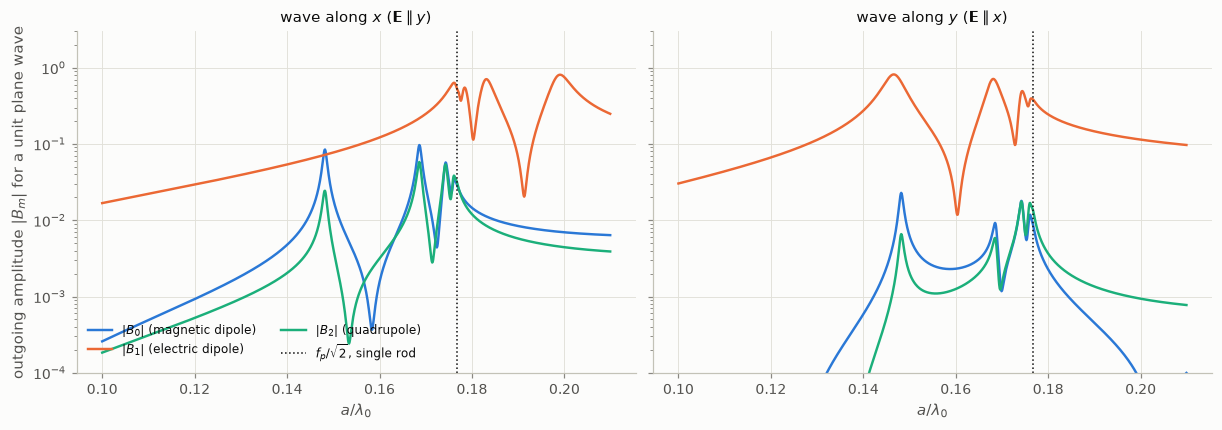

In [6]:
def planewave(L, phi):
    m = np.arange(-L, L + 1)
    return (1j ** m) * np.exp(-1j * m * phi)


def molT(f, fg=0.0, M=12, L=12, r1=R0, r2=R0, gap=GAP):
    return bl.molecule_t_matrix(TWO_PI * f, dimer(r1, r2, gap, drude(f, fg)), "TE", M=M, Lmol=L)


def block(L, parity, sign):
    """Orthonormal basis (columns) of coefficient vectors with |m| of the given parity and a_{-m} = sign * a_m."""
    m = np.arange(-L, L + 1)
    cols = []
    for mm in range(0, L + 1):
        if mm % 2 != parity:
            continue
        v = np.zeros(2 * L + 1, complex)
        if mm == 0:
            if sign < 0:
                continue
            v[m == 0] = 1
        else:
            v[m == mm], v[m == -mm] = 1 / np.sqrt(2), sign / np.sqrt(2)
        cols.append(v)
    return np.array(cols).T


block_A = lambda L: block(L, 0, +1)                         # H_z even under both mirrors: m = 0, cos 2phi, ...
block_D = lambda L: block(L, 1, -1)                         # odd m, cos m phi: the electric dipole p_y and its relatives


LM = 12
t0 = time.time()
fs_iso = np.arange(0.10, 0.21, 0.0001)
curves = {"x": [], "y": []}
for f in fs_iso:
    T = molT(f, FG)
    for key, ph in (("x", 0.0), ("y", np.pi / 2)):
        curves[key].append(np.abs((T @ planewave(LM, ph))[LM:LM + 3]))                 # |B_0|, |B_1|, |B_2|
curves = {k: np.array(v) for k, v in curves.items()}
print(f"{len(fs_iso)} T-matrices in {time.time() - t0:.1f} s")


def peaks_of(y, fs, rel=0.05):
    ix, _ = find_peaks(y, height=rel * y.max())
    return fs[ix]


print("resonances of the weakly lossy dimer (f_gamma = f_p/300), peaks of |B_m|:")
pk = {"antisymmetric, opposite currents along y: |B_0|, wave along x": peaks_of(curves["x"][:, 0], fs_iso),
      "parallel currents along y (electric dipole p_y): |B_1|, wave along x": peaks_of(curves["x"][:, 1], fs_iso),
      "head-to-tail currents along x (electric dipole p_x): |B_1|, wave along y": peaks_of(curves["y"][:, 1], fs_iso)}
for k, v in pk.items():
    print(f"  {k}: {np.round(v[:5], 4)}")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, key, ttl in ((axs[0], "x", r"wave along $x$ ($\mathbf{E}\parallel y$)"), (axs[1], "y", r"wave along $y$ ($\mathbf{E}\parallel x$)")):
    for m, col, lab in ((0, CAT[0], r"$|B_0|$ (magnetic dipole)"), (1, CAT[1], r"$|B_{1}|$ (electric dipole)"), (2, CAT[2], r"$|B_{2}|$ (quadrupole)")):
        ax.semilogy(fs_iso, curves[key][:, m], color=col, label=lab)
    ax.axvline(FP / np.sqrt(2), color=INK, ls=":", lw=1, label=r"$f_p/\sqrt{2}$, single rod")
    ax.set(xlabel=r"$a/\lambda_0$", title=ttl, ylim=(1e-4, 3))
axs[0].set_ylabel(r"outgoing amplitude $|B_m|$ for a unit plane wave"); axs[0].legend(loc="lower left", ncol=2, fontsize=8)
plt.show()

The dimer has several resonances between 0.14 and 0.20 (the printed peak lists, and the curves): the close pair supports a family of gap modes in addition to the dipole modes of the single rod near $f_p/\sqrt2$. Three of them are followed, named by the multipole that responds and by the polarization of the exciting wave. The reading is, at this point, a hypothesis, tested below by the field snapshot and by the multipole content: the lowest peak of $|B_1|$ for the wave along $y$ is the pair of dipoles along the axis in a head-to-tail arrangement (the bonding mode); the lowest peak of $|B_0|$ for the wave along $x$ is the pair of dipoles across the axis in opposition (the antisymmetric mode, magnetic moment $m_z$); and the peak of $|B_1|$ for the wave along $x$ near the single-rod value is the pair of parallel dipoles across the axis. For line dipoles in two dimensions the coupling between two dipoles is the same in magnitude for the head-to-tail and for the side-by-side arrangement (the field of a line dipole falls as $1/r^2$ with the angular factor $2\hat p\cdot\hat r\,\hat r-\hat p$, equal to $+1$ and $-1$ for the two), so the first two modes are expected close together, and the printed lists show that they are (and that the antisymmetric one lies slightly above the bonding one, a difference that comes from the higher multipoles of the rods). The parallel mode is well above them, near the single-rod resonance.

### 2.1 Frequency, width and multipole content of the antisymmetric mode, collisionless

Without loss the mode is a resonance of the block, whose largest eigenvalue of $T$ reaches the unitarity limit of one at the resonance. The maximum of that eigenvalue is found in a bracket around the lossy peak, and its radiative width is measured from the two frequencies at which the eigenvalue has fallen to $1/\sqrt2$.

In [7]:
tA = lambda f, M=12, L=12: np.abs(np.linalg.eigvals(block_A(L).conj().T @ molT(f, 0.0, M, L) @ block_A(L))).max()
f_lossy_A = fs_iso[np.argmax(curves["x"][:, 0][(fs_iso > 0.14) & (fs_iso < 0.155)]) + np.argmax(fs_iso > 0.14)]
res = minimize_scalar(lambda f: -tA(f), bounds=(f_lossy_A - 3e-4, f_lossy_A + 3e-4), method="bounded", options=dict(xatol=1e-12))
F_A_ISO, tmax = res.x, -res.fun
lo = brentq(lambda f: tA(f) - tmax / np.sqrt(2), F_A_ISO - 2e-4, F_A_ISO)
hi = brentq(lambda f: tA(f) - tmax / np.sqrt(2), F_A_ISO, F_A_ISO + 2e-4)
print(f"antisymmetric mode of the isolated dimer, collisionless: f_A = {F_A_ISO:.7f}, largest eigenvalue of T in the block {tmax:.5f}")
print(f"radiative width (half-width points at 1/sqrt 2 of the maximum): {hi - lo:.2e}, quality factor f_A / width = {F_A_ISO / (hi - lo):.0f}")
Q_RAD = F_A_ISO / (hi - lo)
assert Q_RAD > 1000
check("the antisymmetric mode saturates unitarity at its resonance: max eigenvalue of T in the block", tmax, 2e-3, 1.0)

# convergence in the truncations
f_M8 = minimize_scalar(lambda f: -tA(f, 8, 8), bounds=(F_A_ISO - 1e-4, F_A_ISO + 1e-4), method="bounded", options=dict(xatol=1e-12)).x
f_M16 = minimize_scalar(lambda f: -tA(f, 16, 16), bounds=(F_A_ISO - 1e-4, F_A_ISO + 1e-4), method="bounded", options=dict(xatol=1e-12)).x
print(f"f_A for M = L = 8, 12, 16: {f_M8:.7f}, {F_A_ISO:.7f}, {f_M16:.7f}")
check("f_A with M = L = 16 against M = L = 12", f_M16, 2e-6, F_A_ISO)

# unitarity and reciprocity of the T-matrix of the molecule at f_A
T = molT(F_A_ISO, 0.0, 12, 14)
S = np.eye(T.shape[0]) + 2 * T
check("lossless S = I + 2T is unitary at f_A (max |S^+ S - I|; the roundoff is amplified by the quality factor)", np.abs(S.conj().T @ S - np.eye(len(S))).max(), 1e-5)
def unit_err(m_):
    S_ = np.eye(2 * 14 + 1) + 2 * molT(F_A_ISO, 0.0, m_, 14)
    return np.abs(S_.conj().T @ S_ - np.eye(len(S_))).max()


print("unitarity error of S at f_A against the multipole truncation M of the rods (roundoff of the ill-conditioned cluster matrix): " + ", ".join(f"M = {m_}: {unit_err(m_):.1e}" for m_ in (6, 8, 10, 12)))
for f_u in (0.14, 0.17):
    Tu = molT(f_u, 0.0, 12, 14); Su = np.eye(Tu.shape[0]) + 2 * Tu
    check(f"lossless S = I + 2T is unitary away from resonance (f = {f_u}, max |S^+ S - I|)", np.abs(Su.conj().T @ Su - np.eye(len(Su))).max(), 1e-7)
mm = np.arange(-14, 15)
for f_u, tol_u in ((0.14, 1e-7), (F_A_ISO, 1e-5)):
    Tu = molT(f_u, 0.0, 12, 14)
    recip = (-1.0) ** (mm[:, None] + mm[None, :]) * Tu[::-1, ::-1].T
    check(f"reciprocity T[m, m'] = (-1)^(m+m') T[-m', -m] at f = {f_u:.4f} (max difference)", np.abs(Tu - recip).max(), tol_u)

# multipole content of the radiation
T = molT(F_A_ISO, 0.0, 12, 12)
L12 = 12
Bx, By = T @ planewave(L12, 0.0), T @ planewave(L12, np.pi / 2)
mm = np.arange(-L12, L12 + 1)
wts, wts_blk = {}, {}
print("share of the radiated power at f_A in each outgoing order (|B_m|^2 / sum |B|^2), by the exciting wave; and within the block of even m")
print(f"{'':16s} {'m = 0':>9s} {'m = +-1':>9s} {'m = +-2':>9s} {'m = +-3':>9s} {'m = +-4':>9s}   |  {'m = 0':>7s} {'m = +-2':>8s} {'m = +-4':>8s} (even-m block only)")
for key, B in (("wave along x", Bx), ("wave along y", By)):
    w = np.abs(B) ** 2 / (np.abs(B) ** 2).sum()
    wts[key] = [w[mm == 0][0]] + [w[np.abs(mm) == k].sum() for k in (1, 2, 3, 4)]
    wb = np.array([wts[key][0], wts[key][2], wts[key][4]]); wts_blk[key] = wb / wb.sum()
    print(f"{key:16s} " + " ".join(f"{x:9.4f}" for x in wts[key]) + "   |  " + " ".join(f"{x:7.4f}" for x in wts_blk[key]))
print(f"|B_0| of the wave along y over that of the wave along x: {abs(By[L12] / Bx[L12]):.4f}")
check("within the block of even m the radiated shares do not depend on the exciting wave (m = 0 share, x against y)", wts_blk["wave along y"][0], 5e-3, wts_blk["wave along x"][0])

# a single resonance couples to the same combination of orders that it radiates (T symmetric in the cos basis)
BAL = block_A(L12)
a_x, a_y = BAL.conj().T @ planewave(L12, 0.0), BAL.conj().T @ planewave(L12, np.pi / 2)
u = BAL.conj().T @ Bx                                         # radiated pattern, in the block basis
pred = (u @ a_y) / (u @ a_x)
check("excitation by the wave along y relative to that along x, predicted from the radiated orders (T = lambda u u^T)", abs(pred), 0.03 * abs(By[L12] / Bx[L12]), abs(By[L12] / Bx[L12]))
assert wts_blk["wave along x"][0] > wts_blk["wave along x"][1] > 0.05

antisymmetric mode of the isolated dimer, collisionless: f_A = 0.1481844, largest eigenvalue of T in the block 1.00000
radiative width (half-width points at 1/sqrt 2 of the maximum): 5.49e-05, quality factor f_A / width = 2697
PASS  the antisymmetric mode saturates unitarity at its resonance: max eigenvalue of T in the block: got 1, target 1, |diff| 2.13e-07 <= 2e-03
f_A for M = L = 8, 12, 16: 0.1481927, 0.1481844, 0.1481844
PASS  f_A with M = L = 16 against M = L = 12: got 0.148184, target 0.148184, |diff| 3.74e-08 <= 2e-06
PASS  lossless S = I + 2T is unitary at f_A (max |S^+ S - I|; the roundoff is amplified by the quality factor): got 1.39342e-06, target 0, |diff| 1.39e-06 <= 1e-05
unitarity error of S at f_A against the multipole truncation M of the rods (roundoff of the ill-conditioned cluster matrix): M = 6: 4.1e-11, M = 8: 2.9e-09, M = 10: 5.1e-08, M = 12: 1.4e-06
PASS  lossless S = I + 2T is unitary away from resonance (f = 0.14, max |S^+ S - I|): got 7.77624e-09, target 0, |d

**Reading the printed numbers.** The antisymmetric mode is a high-$Q$ resonance, as a small object radiating a magnetic dipole and a quadrupole should be (the printed quality factor is in the thousands; the radiation is presumably weak because the two opposite currents nearly cancel in the far field), at a frequency well below the single-rod resonance and close to, but resolved from, the bonding mode. Its radiated field is mostly the $m=0$ order, with a smaller $m=\pm2$ part and almost nothing else; the table shows the shares for the whole radiated field, and, restricted to the even-$m$ block that the mode lives in, shares that are the same for the two exciting waves (the check), as they must be at resonance, where the radiation is that of the mode. For the wave along $y$ the total radiated field at $f_A$ is dominated by $m=\pm1$: that wave drives the nearby bonding mode, an electric dipole, much more strongly than it drives the antisymmetric one, so only the even-$m$ block isolates the mode.

What depends on the exciting wave is the amplitude. The wave along $x$ (electric field along $y$, the polarization direction of the mode) drives the antisymmetric mode several times more strongly than the wave along $y$. A pure magnetic dipole could not tell the two waves apart, since both have the same $H_z$ at the center ($a_0=1$); the difference comes from the quadrupole part of the mode, which couples to $a_{\pm2}$ with opposite sign for the two waves ($a_{\pm2}=-1$ along $x$, $+1$ along $y$). The check above shows that this is quantitatively right: the ratio predicted from the orders that the mode radiates, using the reciprocity of $T$ ($T\simeq\lambda uu^{\mathsf T}$ in the block, so that the pattern radiated is also the pattern that is received), reproduces the ratio of the two excitations. **The mode is not a pure magnetic dipole: its quadrupole content is what makes the response depend on the direction of the incident wave.** (The share of $m=0$ is an upper bound for the magnetic dipole: in two dimensions the second moments of the current also contribute to the monopole of $H_z$, notebook 01 section 4; the split of the printed $m=0$ share is not attempted.)

### 2.2 Field snapshot

The field is rebuilt from the cluster solution: the coefficients $b^{(j)}_l$ of the outgoing wave about each rod, and the interior coefficients $c_l=(a_lJ_l(k_0R)+b_lH_l(k_0R))/J_l(k_1R)$ with $a_l$ the total regular field on the rod. $\mathbf E=(i/k_0\varepsilon)(\partial_yH_z,-\partial_xH_z)$, with the derivatives taken analytically through $\partial_xf_l=\tfrac k2(f_{l-1}-f_{l+1})$ and $\partial_yf_l=\tfrac{ik}2(f_{l+1}+f_{l-1})$ for $f_l=Z_l(kr)e^{il\phi}$. Nothing is differenced across a rod surface, but $\mathbf E$ jumps there (its normal component by the factor $\varepsilon_m$), so a band of width $0.05R$ around each surface is masked. The cell checks the reconstruction against the $T$-matrix (far field) and against the continuity of $H_z$ and $E_\phi$ at the surface. To show the mode and not its superposition with the other modes that a plane wave also drives, the incident field is the part of the plane wave along $x$ that lies in the symmetry block of the mode (for the antisymmetric mode the even-$m$, $\cos m\phi$ block of the previous cell; for the parallel mode the odd-$m$ block of the same kind), which makes the snapshot symmetric under the mirrors. The arrows give the direction of $\mathrm{Re}\,\mathbf E$ only (normalized length); where the field is strong is read from $H_z$.

PASS  far field from the rod coefficients against molecule_t_matrix at f = 0.14 (relative; roundoff of the ill-conditioned cluster matrix at M = 12): got 5.64558e-08, target 0, |diff| 5.65e-08 <= 1e-06
PASS  far field from the rod coefficients against molecule_t_matrix at f_A (relative; the resonance amplifies roundoff): got 5.70109e-08, target 0, |diff| 5.70e-08 <= 1e-06
PASS  H_z continuous across the rod surfaces (relative jump; limited by the truncation of the regular expansion in the 0.06 gap): got 8.8326e-05, target 0, |diff| 8.83e-05 <= 3e-04
PASS  E_phi continuous across the rod surfaces (relative jump): got 0.00131152, target 0, |diff| 1.31e-03 <= 3e-03


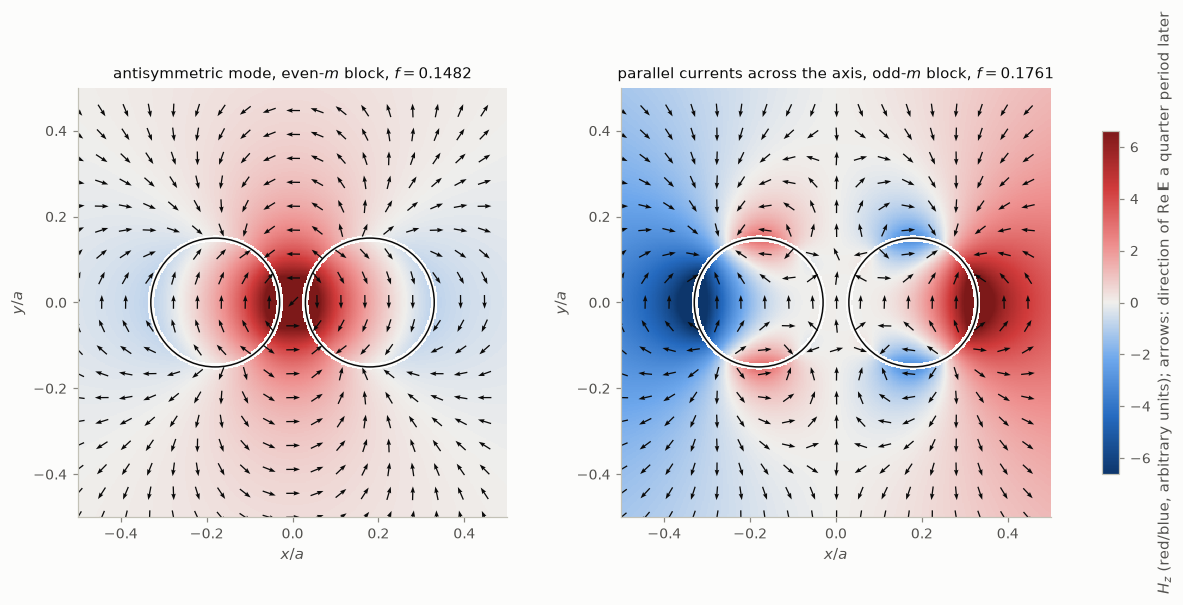

In [8]:
def cluster_solve(k0, rods, M, a0, L):
    """Outgoing coefficients b (N, 2M+1) about each rod and the total regular coefficients a (N, 2M+1) at each rod, for the incident a0 about the origin."""
    N, nl = len(rods), 2 * M + 1
    t = bl._mie(rods, k0, "TE", M)
    big = np.eye(N * nl, dtype=complex)
    Rr = [bl.regular_translation(k0, r.d, L, M) for r in rods]
    C = {(i, j): bl.outgoing_to_regular(k0, rods[j].d - rods[i].d, M) for i in range(N) for j in range(N) if i != j}
    for (i, j), Cij in C.items():
        big[i * nl:(i + 1) * nl, j * nl:(j + 1) * nl] -= t[i][:, None] * Cij
    b = np.linalg.solve(big, np.concatenate([t[i] * (Rr[i] @ a0) for i in range(N)])).reshape(N, nl)
    a = np.array([Rr[i] @ a0 + sum(C[(i, j)] @ b[j] for j in range(N) if j != i) for i in range(N)])
    return b, a


def series(coef, kk, r, ph, order_max, kind):
    """Value and gradient of sum_l coef_l Z_l(kk r) e^{i l ph} at the points (r, ph); kind: 'H' (outgoing) or 'J'."""
    l = np.arange(-order_max - 1, order_max + 2)
    Z = (hankel1 if kind == "H" else jv)(l[None, :], kk * r[:, None]) * np.exp(1j * l[None, :] * ph[:, None])
    cf = np.zeros(len(l), complex); cf[1:-1] = coef
    val = Z[:, 1:-1] @ coef
    gx = (kk / 2) * ((Z[:, :-2] - Z[:, 2:]) @ coef)
    gy = (1j * kk / 2) * ((Z[:, 2:] + Z[:, :-2]) @ coef)
    return val, gx, gy


def cluster_fields(k0, rods, b, a, a0, x, y, M):
    """H_z and E = (Ex, Ey) of the cluster driven by the incident field sum_m a0_m J_m e^{im phi}, at the points (x, y)."""
    H, Gx, Gy = series(a0, k0, np.hypot(x, y), np.arctan2(y, x), (len(a0) - 1) // 2, "J")
    eps_pt = np.ones(x.shape, complex)
    inside = np.zeros(x.shape, bool)
    l = np.arange(-M, M + 1)
    for j, rd in enumerate(rods):                       # scattered fields of every rod, at the points outside it
        dx, dy = x - rd.d[0], y - rd.d[1]
        r, ph = np.hypot(dx, dy), np.arctan2(dy, dx)
        out = r > rd.radius
        if out.any():
            v, gx, gy = series(b[j], k0, r[out], ph[out], M, "H")
            H[out] += v; Gx[out] += gx; Gy[out] += gy
    for j, rd in enumerate(rods):                       # the interior solution replaces everything inside a rod
        dx, dy = x - rd.d[0], y - rd.d[1]
        r, ph = np.hypot(dx, dy), np.arctan2(dy, dx)
        inn = r <= rd.radius
        if inn.any():
            k1 = k0 * np.sqrt(complex(rd.eps))
            c = (a[j] * jv(l, k0 * rd.radius) + b[j] * hankel1(l, k0 * rd.radius)) / jv(l, k1 * rd.radius)
            v, gx, gy = series(c, k1, r[inn], ph[inn], M, "J")
            H[inn], Gx[inn], Gy[inn] = v, gx, gy
            eps_pt[inn] = complex(rd.eps); inside |= inn
    return H, (1j / (k0 * eps_pt)) * Gy, -(1j / (k0 * eps_pt)) * Gx, inside


# validation: far field from the rod coefficients against the T-matrix, and continuity at the rod surface
Mc, Lc = 12, 14
rods_s = dimer(R0, R0, GAP, drude(F_A_ISO))
k0s = TWO_PI * F_A_ISO
a0x = planewave(Lc, 0.0)
b_s, a_s = cluster_solve(k0s, rods_s, Mc, a0x, Lc)
def far_vs_T(f):
    rods_f, k0f = dimer(R0, R0, GAP, drude(f)), TWO_PI * f
    b_f, _ = cluster_solve(k0f, rods_f, Mc, a0x, Lc)
    Bf = sum(bl.outgoing_translation(k0f, rd.d, Lc, Mc) @ b_f[j] for j, rd in enumerate(rods_f))
    return np.abs(Bf - molT(f, 0.0, Mc, Lc) @ a0x).max() / np.abs(Bf).max()


check("far field from the rod coefficients against molecule_t_matrix at f = 0.14 (relative; roundoff of the ill-conditioned cluster matrix at M = 12)", far_vs_T(0.14), 1e-6)
check("far field from the rod coefficients against molecule_t_matrix at f_A (relative; the resonance amplifies roundoff)", far_vs_T(F_A_ISO), 1e-6)
th = np.linspace(0, 2 * np.pi, 37)[:-1] + 0.1
worst_H = worst_E = 0.0
for j, rd in enumerate(rods_s):
    for eps_ in (1e-9,):
        xo, yo = rd.d[0] + (rd.radius + eps_) * np.cos(th), rd.d[1] + (rd.radius + eps_) * np.sin(th)
        xi, yi = rd.d[0] + (rd.radius - eps_) * np.cos(th), rd.d[1] + (rd.radius - eps_) * np.sin(th)
        Ho, Exo, Eyo, _ = cluster_fields(k0s, rods_s, b_s, a_s, a0x, xo, yo, Mc)
        Hi, Exi, Eyi, _ = cluster_fields(k0s, rods_s, b_s, a_s, a0x, xi, yi, Mc)
        Eto, Eti = -Exo * np.sin(th) + Eyo * np.cos(th), -Exi * np.sin(th) + Eyi * np.cos(th)
        worst_H = max(worst_H, np.abs(Ho - Hi).max() / np.abs(Ho).max())
        worst_E = max(worst_E, np.abs(Eto - Eti).max() / np.abs(Eto).max())
check("H_z continuous across the rod surfaces (relative jump; limited by the truncation of the regular expansion in the 0.06 gap)", worst_H, 3e-4)
check("E_phi continuous across the rod surfaces (relative jump)", worst_E, 3e-3)


def snapshot(ax, f, blockV, title, extent=0.5, n=360, band=0.05):
    """H_z and E of the cluster driven by the part of a wave along x that lies in the symmetry block blockV (columns)."""
    rods_ = dimer(R0, R0, GAP, drude(f)); k0_ = TWO_PI * f
    a0_ = blockV @ (blockV.conj().T @ planewave(Lc, 0.0))
    b_, a_ = cluster_solve(k0_, rods_, Mc, a0_, Lc)
    xs = np.linspace(-extent, extent, n)
    X, Y = np.meshgrid(xs, xs)
    H, Ex, Ey, inside = cluster_fields(k0_, rods_, b_, a_, a0_, X.ravel(), Y.ravel(), Mc)
    H, Ex, Ey = H.reshape(X.shape), Ex.reshape(X.shape), Ey.reshape(X.shape)
    d_surf = np.min([np.abs(np.hypot(X - rd.d[0], Y - rd.d[1]) - rd.radius) for rd in rods_], axis=0)
    masked = d_surf < band * R0
    ref = np.argmax(np.where(masked, 0, np.abs(H)))
    ph = np.exp(-1j * np.angle(H.ravel()[ref]))
    Em = np.where(masked, 0, np.hypot(np.abs(Ex), np.abs(Ey)))
    iE = np.unravel_index(np.argmax(Em), Em.shape)
    phE = np.exp(-1j * np.angle(Ex[iE] if abs(Ex[iE]) > abs(Ey[iE]) else Ey[iE]))   # E at its own maximum phase (a quarter period from H_z at a standing resonance)
    Hr = np.where(masked, np.nan, (H * ph).real)
    lim = np.nanpercentile(np.abs(Hr), 99.0)
    im = ax.imshow(Hr, extent=(-extent, extent, -extent, extent), cmap="div_blue_red", vmin=-lim, vmax=lim)
    st = 20
    U, V = np.where(masked, np.nan, (Ex * phE).real)[::st, ::st], np.where(masked, np.nan, (Ey * phE).real)[::st, ::st]
    nrm = np.hypot(U, V)
    ax.quiver(X[::st, ::st], Y[::st, ::st], U / nrm, V / nrm, color=INK, pivot="mid", angles="xy", scale_units="xy", scale=1 / 0.032, width=0.003, headwidth=3.5)
    for rd in rods_:
        ax.add_patch(plt.Circle(rd.d, rd.radius, fill=False, ec=INK, lw=1.0))
    ax.set(xlabel=r"$x/a$", ylabel=r"$y/a$", title=title, aspect="equal", xlim=(-extent, extent), ylim=(-extent, extent))
    ax.grid(False)
    return im


f_S = peaks_of(curves["x"][:, 1], fs_iso)[0]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
snapshot(axs[0], F_A_ISO, block_A(Lc), rf"antisymmetric mode, even-$m$ block, $f={F_A_ISO:.4f}$")
im = snapshot(axs[1], f_S, block_D(Lc), rf"parallel currents across the axis, odd-$m$ block, $f={f_S:.4f}$")
fig.colorbar(im, ax=axs, shrink=0.8, label=r"$H_z$ (red/blue, arbitrary units); arrows: direction of $\mathrm{Re}\,\mathbf{E}$ a quarter period later")
plt.show()

**Left (the antisymmetric mode).** $H_z$ has one sign in the region between the rods and a weaker opposite sign outside, so the pattern is that of a magnetic dipole ($m=0$) with a quadrupole correction. The arrows show that the electric field points up in the left rod and down in the right one and closes through the surrounding space: the two rods carry opposite currents along $y$, which together make a current loop around the center of the dimer, and the red lobe is its magnetic moment. **Right (the other mode).** $H_z$ is odd across the axis and the field in the two rods points the same way: parallel currents, an electric dipole $p_y$. These are the pictures behind the names used above; the snapshot is of the field driven by the symmetry-matched part of a plane wave, which is why it is symmetric under the mirrors.

## 3. The lattice of symmetric dimers

**Method.** $\varepsilon(\omega,\mathbf k)$ from `basislattice.driven` for real or complex $\mathbf k=\kappa\hat{\mathbf k}$, and its Taylor coefficients in $\kappa$ as Cauchy integrals over a circle $|\kappa|=\rho$ (trapezoid rule on six points, spectrally accurate as in notebook 03). Three directions give all five coefficients: $\alpha_{xx;xx}$ and $\alpha_{yy;xx}$ from $\kappa^2$ along $x$ (longitudinal, transverse), $\alpha_{xx;yy}$ and $\alpha_{yy;yy}$ along $y$ (transverse, longitudinal), and $\alpha_{xy;xy}$ from the off-diagonal element at $45^\circ$, where $\varepsilon_{xy}=\alpha_{xy;xy}\kappa^2$. The multipole truncation is $M=10$ for every rod: near a resonance the pole position is sensitive to it, and the cell below prints this. A fourth direction ($30^\circ$) tests that the five numbers reproduce the whole tensor.

In [9]:
M_LAT, RHO, NCAU = 10, 0.01, 6


def taylor_tensor(f, fg, phi, rods=None, rho=RHO, n=NCAU, M=M_LAT, orders=(0, 1, 2, 3)):
    """Taylor coefficients (orders, 2, 2) of eps(w, kappa (cos phi, sin phi)) in kappa from n points on |kappa| = rho."""
    rods = dimer(R0, R0, GAP, drude(f, fg)) if rods is None else rods
    k0 = TWO_PI * f
    kh = np.array([np.cos(phi), np.sin(phi)])
    th = (np.arange(n) + 0.5) * TWO_PI / n
    vals = np.array([bl.driven(k0, rho * np.exp(1j * t) * kh, rods, "TE", M=M)[0] for t in th])
    return np.array([np.tensordot(np.exp(-1j * m * th), vals, axes=(0, 0)) / n / rho**m for m in orders])


def lattice_point(f, fg=0.0, **kw):
    """The five second-order coefficients (complex), eps(w, 0) and diagnostics for the symmetric dimer."""
    cx, cy, cd = (taylor_tensor(f, fg, p, **kw) for p in (0.0, np.pi / 2, np.pi / 4))
    A = np.array([cx[2][0, 0], cx[2][1, 1], cy[2][0, 0], cy[2][1, 1], cd[2][0, 1]])
    scale = np.abs(A).max()
    diag = dict(odd=max(np.abs(c[[1, 3]]).max() for c in (cx, cy, cd)) * kw.get("rho", RHO) / max(np.abs(cx[0]).max(), 1e-300),
                forbidden=max(abs(cx[2][0, 1]), abs(cy[2][0, 1])) / scale)
    return A, cx[0], diag


print("(a) convergence of the second-order coefficients at a frequency off resonance (f = 0.12) and one close to the antisymmetric mode")
f_probe = {"f = 0.12": 0.12, "f = 0.1472": 0.1472}
for name, f in f_probe.items():
    A8 = lattice_point(f, M=8)[0]
    A10 = lattice_point(f, M=10)[0]
    A12 = lattice_point(f, M=12)[0]
    Ar = lattice_point(f, M=10, rho=0.004)[0]
    Ar2 = lattice_point(f, M=10, rho=0.02)[0]
    print(f"    {name}: relative change M 8 -> 12 {np.abs(A8 - A12).max() / np.abs(A12).max():.1e}, M 10 -> 12 {np.abs(A10 - A12).max() / np.abs(A12).max():.1e}; radius 0.004 / 0.02 vs 0.01: "
          f"{np.abs(Ar - A10).max() / np.abs(A10).max():.1e} / {np.abs(Ar2 - A10).max() / np.abs(A10).max():.1e}")
    check(f"(a) {name}: Cauchy radius 0.004 against 0.02 (relative)", np.abs(Ar - Ar2).max() / np.abs(A10).max(), 1e-4 if f < 0.14 else 3e-3)
    check(f"(a) {name}: M = 10 against M = 12 (relative)", np.abs(A10 - A12).max() / np.abs(A12).max(), 3e-2 if f > 0.14 else 3e-4)

(a) convergence of the second-order coefficients at a frequency off resonance (f = 0.12) and one close to the antisymmetric mode


    f = 0.12: relative change M 8 -> 12 1.6e-04, M 10 -> 12 1.5e-04; radius 0.004 / 0.02 vs 0.01: 1.2e-05 / 1.6e-06
PASS  (a) f = 0.12: Cauchy radius 0.004 against 0.02 (relative): got 1.26703e-05, target 0, |diff| 1.27e-05 <= 1e-04
PASS  (a) f = 0.12: M = 10 against M = 12 (relative): got 0.000147726, target 0, |diff| 1.48e-04 <= 3e-04


    f = 0.1472: relative change M 8 -> 12 1.3e-02, M 10 -> 12 1.2e-03; radius 0.004 / 0.02 vs 0.01: 9.1e-06 / 1.2e-06
PASS  (a) f = 0.1472: Cauchy radius 0.004 against 0.02 (relative): got 9.11538e-06, target 0, |diff| 9.12e-06 <= 3e-03
PASS  (a) f = 0.1472: M = 10 against M = 12 (relative): got 0.0011795, target 0, |diff| 1.18e-03 <= 3e-02


In [10]:
print("(b) symmetry checks of the extraction, symmetric dimer, collisionless, f = 0.12")
A, e0, diag = lattice_point(0.12)
check("(b) odd orders in kappa vanish (kappa c_1 and kappa c_3 against eps(0))", diag["odd"], 1e-6)
check("(b) the second-order xy element is zero along x and along y (relative)", diag["forbidden"], 1e-5)
check("(b) lossless rods: the five coefficients are real (max imaginary part, relative)", np.abs(A.imag).max() / np.abs(A).max(), 1e-5)
c30 = taylor_tensor(0.12, 0.0, np.pi / 6)
Qk = lambda p: np.einsum("ijlm,l,m->ij", alpha_from_five(A), *(2 * [np.array([np.cos(p), np.sin(p)])]))
check("(b) the five coefficients reproduce the full second-order tensor along 30 degrees (relative)", np.abs(c30[2] - Qk(np.pi / 6)).max() / np.abs(c30[2]).max(), 1e-5)

k_gen = (0.31, -0.22)
k0g = TWO_PI * 0.12
e_p = bl.driven(k0g, k_gen, dimer(R0, R0, GAP, drude(0.12)), "TE", M=M_LAT)[0]
e_m = bl.driven(k0g, (-k_gen[0], -k_gen[1]), dimer(R0, R0, GAP, drude(0.12)), "TE", M=M_LAT)[0]
check("(b) reciprocity eps(k) = eps(-k)^T at a generic k (max difference)", np.abs(e_p - e_m.T).max(), 1e-8)
check("(b) lossless, real k: eps is real symmetric (inversion-symmetric cell; max of imaginary part and asymmetry)", np.abs(e_p.imag).max() + abs(e_p[0, 1] - e_p[1, 0]), 1e-8)
e_l = bl.driven(k0g, k_gen, dimer(R0, R0, GAP, drude(0.12, FG)), "TE", M=M_LAT)[0]
anti = (e_l - e_l.conj().T) / 2j
check("(b) lossy rods, real k: the absorbing part of eps is positive semidefinite (most negative eigenvalue)", min(np.linalg.eigvalsh(anti).min(), 0.0), 1e-12)
assert np.linalg.eigvalsh(anti).min() > 0

(b) symmetry checks of the extraction, symmetric dimer, collisionless, f = 0.12
PASS  (b) odd orders in kappa vanish (kappa c_1 and kappa c_3 against eps(0)): got 7.38422e-08, target 0, |diff| 7.38e-08 <= 1e-06
PASS  (b) the second-order xy element is zero along x and along y (relative): got 8.33595e-07, target 0, |diff| 8.34e-07 <= 1e-05
PASS  (b) lossless rods: the five coefficients are real (max imaginary part, relative): got 1.12755e-06, target 0, |diff| 1.13e-06 <= 1e-05
PASS  (b) the five coefficients reproduce the full second-order tensor along 30 degrees (relative): got 6.32111e-06, target 0, |diff| 6.32e-06 <= 1e-05
PASS  (b) reciprocity eps(k) = eps(-k)^T at a generic k (max difference): got 1.35304e-10, target 0, |diff| 1.35e-10 <= 1e-08
PASS  (b) lossless, real k: eps is real symmetric (inversion-symmetric cell; max of imaginary part and asymmetry): got 2.47419e-11, target 0, |diff| 2.47e-11 <= 1e-08
PASS  (b) lossy rods, real k: the absorbing part of eps is positive semide

### 3.1 Lattice modes and the dispersion condition

For metal rods the permittivity depends on frequency, so the Bloch modes are the zeros, in $f$, of the Hermitian multiple-scattering form of `basislattice.kkr_hermitian` evaluated with $\varepsilon_m(f)$. That function takes the Mie quantities $p_l,q_l$ from `rodlattice.mie_pq`, which uses a real square root and is undefined for negative $\varepsilon$; the Hermitian form is therefore rebuilt here with a complex square root (for $\varepsilon_m<0$ both $p_l$ and $q_l$ carry the common phase $i^{|l|}$, which cancels in $t_l=-p_l/(p_l+iq_l)$ and in $q_l/p_l$, so it is divided out). The scan counts the negative eigenvalues of the form along the frequency axis and bisects each crossing. As a test the function reproduces `basislattice.bloch_frequencies` for a dielectric rod pair; for the metal it is tested by the dispersion condition itself, which comes from a different calculation (the source-driven response).

In [11]:
def pq_complex(l, k0, R, eps):
    """Real p_l, q_l (TE) of a lossless rod, for eps of either sign: p and q of rodlattice.mie_pq with a complex square root, common phase removed."""
    l = np.abs(np.asarray(l)); k1 = k0 * np.sqrt(complex(eps)); q1 = 1.0 / eps
    x0, x1 = k0 * R, k1 * R
    p = q1 * k1 * jvp(l, x1) * jv(l, x0) - k0 * jv(l, x1) * jvp(l, x0)
    q = q1 * k1 * jvp(l, x1) * yv(l, x0) - k0 * jv(l, x1) * yvp(l, x0)
    if eps < 0:
        p, q = p / 1j**l, q / 1j**l
    assert np.abs(p.imag).max() <= 1e-9 * np.abs(p).max() and np.abs(q.imag).max() <= 1e-9 * np.abs(q).max()
    return p.real, q.real


def kkr_hermitian_any(k0, kB, rods, M):
    """Scaled Hermitian form (zero eigenvalue = Bloch mode), TE, lossless rods of either sign of eps (see the text)."""
    Gtab = bl.sums_table(k0, kB, rods, 2 * M)
    delta = (np.arange(-2 * M, 2 * M + 1) == 0)
    for i in range(len(rods)):
        Gtab[i, i] = Gtab[i, i] + delta
    Nb = bl._toeplitz_block(Gtab / 1j, M)
    l = np.arange(-M, M + 1)
    pq = [pq_complex(l, k0, r.radius, r.eps) for r in rods]
    p, q = np.concatenate([x[0] for x in pq]), np.concatenate([x[1] for x in pq])
    lam = np.sqrt(np.abs(p) / (np.abs(p) + np.abs(q)))
    H = lam[:, None] * (np.diag(q / p) + Nb) * lam[None, :]
    return 0.5 * (H + H.conj().T)


def bloch_modes(kB, rods_of_f, M=M_LAT, fr=(0.05, 0.235), n=300):
    """a/lambda0 of the Bloch modes at real kB, for rods_of_f(f) = list of lossless rods at frequency f."""
    def ev(f):
        H = kkr_hermitian_any(TWO_PI * f, kB, rods_of_f(f), M)
        return np.linalg.eigvalsh(H) if np.isfinite(H).all() else None
    fs = np.linspace(fr[0], fr[1], n)
    E = [ev(f) for f in fs]
    ok = np.array([e is not None for e in E]); fs, E = fs[ok], np.array([e for e in E if e is not None])
    nneg = (E < 0).sum(1)
    roots = []
    for i in np.nonzero(nneg[1:] != nneg[:-1])[0]:
        for j in range(min(nneg[i], nneg[i + 1]), max(nneg[i], nneg[i + 1])):
            gj = lambda x: ev(x)[j]
            if gj(fs[i]) * gj(fs[i + 1]) >= 0:
                continue
            fr_ = brentq(gj, fs[i], fs[i + 1], xtol=1e-13)
            if max(abs(gj(fr_ - 1e-8)), abs(gj(fr_ + 1e-8))) < 1e-3 * min(abs(E[i, j]), abs(E[i + 1, j])) + 1e-6:
                roots.append(fr_)
    return np.sort(np.array(roots))


# test 1: a dielectric pair against basislattice.bloch_frequencies
rods_d = lambda f: dimer(R0, R0, GAP, 12.0)
kB_t = (0.9, 0.4)
mine = bloch_modes(kB_t, rods_d, M=6, fr=(0.02, 0.8), n=400)
ref = bl.bloch_frequencies(kB_t, rods_d(0.1), "TE", M=6, fmax=0.8, nscan=400, fmin=0.02)
print(f"dielectric pair, kB = {kB_t}: {len(mine)} modes from the rebuilt form, {len(ref)} from basislattice; lowest three {np.round(mine[:3], 6)} vs {np.round(ref[:3], 6)}")
check("rebuilt Hermitian form against basislattice.bloch_frequencies (dielectric pair, max difference)", np.abs(mine[:len(ref)] - ref).max(), 1e-9)
assert len(mine) == len(ref)

# the lattice mode of the antisymmetric kind: a flat band at the Gamma point
rods_m = lambda f: dimer(R0, R0, GAP, drude(f))
t0 = time.time()
band_pts = [(0.01, 0.0), (0.02, 0.0), (0.04, 0.0), (0.0, 0.02)]
band = [bloch_modes(kB, rods_m, fr=(0.1465, 0.1495), n=30) for kB in band_pts]
print("Bloch modes of the symmetric lattice near the antisymmetric resonance (the only one between 0.1465 and 0.1495):")
for kB, b in zip(band_pts, band):
    print(f"   kB = {kB}: f = {np.round(b, 8)}")
F_A_LAT = band[0][0]
assert all(len(b) == 1 for b in band)
f_A_M = {m_: bloch_modes((0.02, 0.0), rods_m, M=m_, fr=(0.1465, 0.1495), n=30)[0] for m_ in (8, 10, 12)}
print("antisymmetric band at kB = (0.02, 0) against the multipole truncation: " + ", ".join(f"M = {m_}: {v:.7f}" for m_, v in f_A_M.items()))
check("band frequency, M = 10 against M = 12", f_A_M[10], 2e-6, f_A_M[12])
print(f"lattice antisymmetric mode at Gamma, f_A(lattice) = {F_A_LAT:.7f}  (isolated dimer: {F_A_ISO:.7f}); the band is flat: f(kappa = 0.04) - f(kappa = 0.01) = {band[2][0] - band[0][0]:.1e} along x")
assert abs(band[2][0] - band[0][0]) < 1e-5

dielectric pair, kB = (0.9, 0.4): 4 modes from the rebuilt form, 4 from basislattice; lowest three [0.140151 0.653406 0.699329] vs [0.140151 0.653406 0.699329]
PASS  rebuilt Hermitian form against basislattice.bloch_frequencies (dielectric pair, max difference): got 0, target 0, |diff| 0.00e+00 <= 1e-09


Bloch modes of the symmetric lattice near the antisymmetric resonance (the only one between 0.1465 and 0.1495):
   kB = (0.01, 0.0): f = [0.14773837]
   kB = (0.02, 0.0): f = [0.14773843]
   kB = (0.04, 0.0): f = [0.14773868]
   kB = (0.0, 0.02): f = [0.14773839]


antisymmetric band at kB = (0.02, 0) against the multipole truncation: M = 8: 0.1477453, M = 10: 0.1477384, M = 12: 0.1477377
PASS  band frequency, M = 10 against M = 12: got 0.147738, target 0.147738, |diff| 6.95e-07 <= 2e-06
lattice antisymmetric mode at Gamma, f_A(lattice) = 0.1477384  (isolated dimer: 0.1481844); the band is flat: f(kappa = 0.04) - f(kappa = 0.01) = 3.1e-07 along x


In [12]:
print("(c) the dispersion condition det[k0^2 eps - (k^2 I - k k^T)] = 0 at Bloch modes found independently (kB along x, kappa = 0.8)")
kappa_c = 0.8
modes_c = bloch_modes((kappa_c, 0.0), rods_m, fr=(0.05, 0.172), n=260)
seen_T, seen_L, unseen = [], [], []
for f in modes_c:
    k0 = TWO_PI * f
    e = bl.driven(k0, (kappa_c, 0.0), dimer(R0, R0, GAP, drude(f)), "TE", M=M_LAT)[0]
    rT, rL = abs(k0**2 * e[1, 1] - kappa_c**2) / kappa_c**2, abs(e[0, 0])
    (seen_T if rT < 1e-6 else seen_L if rL < 1e-6 else unseen).append((f, rT, rL))
print(f"   {len(modes_c)} Bloch modes between 0.05 and 0.172: {len(seen_T)} satisfy k^2 = k0^2 eps_T (|residual|/k^2 < 1e-6), "
      f"{len(seen_L)} satisfy eps_L = 0 (longitudinal), {len(unseen)} are not seen by the macroscopic response")
for f, rT, rL in seen_T[:4]:
    print(f"      transverse mode f = {f:.6f}: |k0^2 eps_yy - k^2| / k^2 = {rT:.1e}")
assert len(seen_T) >= 2
check("(c) the transverse modes seen by the response: residual of the dispersion condition (largest)", max(r[1] for r in seen_T), 1e-6)
modes_cy = bloch_modes((0.0, kappa_c), rods_m, fr=(0.05, 0.16), n=200)
res_y = []
for f in modes_cy:
    k0 = TWO_PI * f
    e = bl.driven(k0, (0.0, kappa_c), dimer(R0, R0, GAP, drude(f)), "TE", M=M_LAT)[0]
    res_y.append(abs(k0**2 * e[0, 0] - kappa_c**2) / kappa_c**2)
print(f"   kB along y: transverse residuals of the modes below 0.16: {np.array2string(np.array(res_y), precision=1)}")
check("(c) kB along y: the lowest mode (E along x), residual of the dispersion condition", res_y[0], 1e-6)

(c) the dispersion condition det[k0^2 eps - (k^2 I - k k^T)] = 0 at Bloch modes found independently (kB along x, kappa = 0.8)


   5 Bloch modes between 0.05 and 0.172: 2 satisfy k^2 = k0^2 eps_T (|residual|/k^2 < 1e-6), 2 satisfy eps_L = 0 (longitudinal), 1 are not seen by the macroscopic response
      transverse mode f = 0.106897: |k0^2 eps_yy - k^2| / k^2 = 3.3e-13
      transverse mode f = 0.147917: |k0^2 eps_yy - k^2| / k^2 = 1.2e-08
PASS  (c) the transverse modes seen by the response: residual of the dispersion condition (largest): got 1.20185e-08, target 0, |diff| 1.20e-08 <= 1e-06


   kB along y: transverse residuals of the modes below 0.16: [1.7e-11 4.0e-07 5.8e-11]
PASS  (c) kB along y: the lowest mode (E along x), residual of the dispersion condition: got 1.66476e-11, target 0, |diff| 1.66e-11 <= 1e-06


Every transverse mode that the driven response sees satisfies $k^2=k_0^2\varepsilon_T$ to the printed residuals (asserted along $x$, and for the lowest mode along $y$; one higher mode along $y$ has a larger printed residual, which is not asserted), from two calculations that share only the rod model: the Hermitian multiple-scattering form, whose zero is a Bloch mode, and the source-driven response, which was never told where the modes are. This also tests the metal path of the response (negative permittivity), for which a plane-wave expansion is not available (section 3.4). The Bloch modes that the response does not see are the ones that notebook 03 found: modes odd under the mirror that contains $\mathbf k$ carry no macroscopic field, so $\varepsilon(\omega,\mathbf k)$ has no pole there (the printed count of the unseen ones is a count, and that reading of them is notebook 03's, not tested again here). The antisymmetric band is flat (printed) and has no pole in $\varepsilon(\omega,0)$: it is dark at $\mathbf k=0$ and couples to the macroscopic fields only through the first power of $\kappa$ in the field, which is what makes its contribution a second-order coefficient.

In [13]:
def scan_lattice(freqs, fg):
    out = []
    for f in freqs:
        A, e0, _ = lattice_point(f, fg)
        out.append(np.concatenate([A, [e0[0, 0], e0[1, 1]]]))
    return np.array(out)


t0 = time.time()
f_wide = np.unique(np.concatenate([np.linspace(0.03, 0.12, 19), np.linspace(0.12, 0.19, 281)]))
S0 = scan_lattice(f_wide, 0.0)                                      # collisionless
print(f"collisionless scan, {len(f_wide)} frequencies: {time.time() - t0:.0f} s")
K2 = (TWO_PI * f_wide) ** 2
cX, cY, cD = (np.array([cT_phi(a, p) for a in S0[:, :5]]) for p in (0.0, np.pi / 2, np.pi / 4))
tau0 = 0.25 * (cX + cY + 2 * cD)

collisionless scan, 299 frequencies: 19 s


poles on the collisionless grid (local maxima of |.|), a/lambda_0:
   eps_xx(w, 0), |eps| > 30:         [0.1365 0.1645]
   eps_yy(w, 0), |eps| > 30:         [0.175  0.1772 0.1812]
   k0^2 c_T along x,  > 1.5:          [0.1478 0.1672 0.173  0.1755 0.1772 0.1812]
   k0^2 c_T along y,  > 1.5:          [0.1365 0.1645 0.1672 0.173 ]
   k0^2 c_T along the diagonal, > 1.5: [0.1365 0.1478 0.1645 0.1672 0.173  0.175  0.1755 0.1772 0.1778 0.1812]


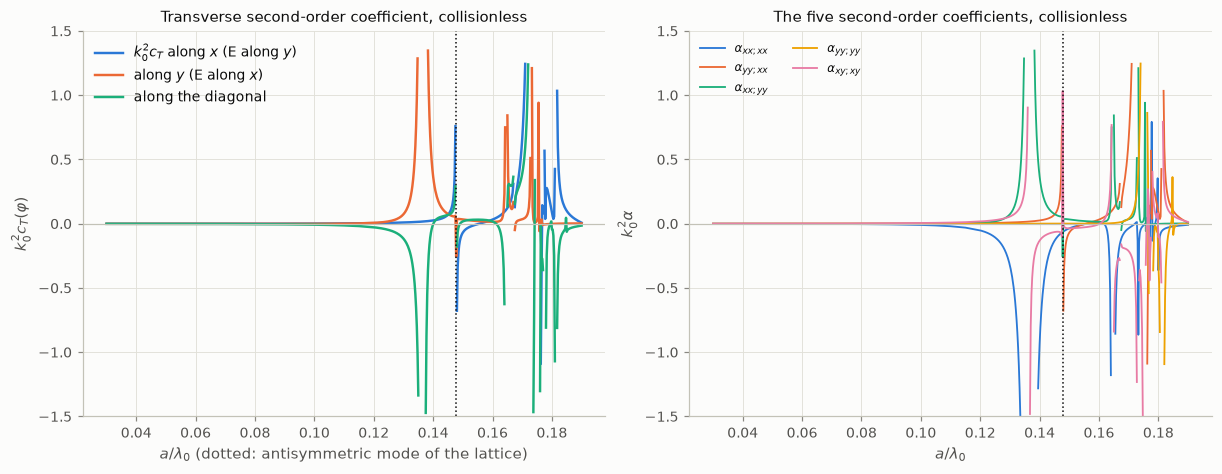

In [14]:
def poles(y, thr):
    ix, _ = find_peaks(np.abs(y), height=thr)
    return np.round(f_wide[ix], 4)


print("poles on the collisionless grid (local maxima of |.|), a/lambda_0:")
print("   eps_xx(w, 0), |eps| > 30:        ", poles(S0[:, 5].real, 30))
print("   eps_yy(w, 0), |eps| > 30:        ", poles(S0[:, 6].real, 30))
print("   k0^2 c_T along x,  > 1.5:         ", poles(K2 * cX.real, 1.5))
print("   k0^2 c_T along y,  > 1.5:         ", poles(K2 * cY.real, 1.5))
print("   k0^2 c_T along the diagonal, > 1.5:", poles(K2 * cD.real, 1.5))

# collisionless: signed log scale of k0^2 c_T along the three directions, mu from them
def clip_poles(y, lim):
    y = y.real.copy(); y[np.abs(y) > lim] = np.nan
    return y


fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axs[0]
for c, col, lab in ((cX, CAT[0], r"$k_0^2c_T$ along $x$ (E along $y$)"), (cY, CAT[1], r"along $y$ (E along $x$)"), (cD, CAT[2], r"along the diagonal")):
    ax.plot(f_wide, clip_poles(K2 * c.real, 1.5), color=col, label=lab)
ax.axvline(F_A_LAT, color=INK, ls=":", lw=1); ax.axhline(0, color=AXIS, lw=0.8)
ax.set(xlabel=r"$a/\lambda_0$ (dotted: antisymmetric mode of the lattice)", ylabel=r"$k_0^2c_T(\varphi)$", ylim=(-1.5, 1.5), title="Transverse second-order coefficient, collisionless")
ax.legend(loc="upper left")
ax = axs[1]
for A_, col, lab in ((0, CAT[0], r"$\alpha_{xx;xx}$"), (1, CAT[1], r"$\alpha_{yy;xx}$"), (2, CAT[2], r"$\alpha_{xx;yy}$"), (3, CAT[3], r"$\alpha_{yy;yy}$"), (4, CAT[4], r"$\alpha_{xy;xy}$")):
    ax.plot(f_wide, clip_poles(K2 * S0[:, A_], 1.5), color=col, label=lab, lw=1.2)
ax.axvline(F_A_LAT, color=INK, ls=":", lw=1); ax.axhline(0, color=AXIS, lw=0.8)
ax.set(xlabel=r"$a/\lambda_0$", ylabel=r"$k_0^2\alpha$", ylim=(-1.5, 1.5), title="The five second-order coefficients, collisionless")
ax.legend(loc="upper left", ncol=2, fontsize=8)
plt.show()

Each curve diverges at the poles of the lattice (printed lists above the figure) and is cut at the plot limit. The structure at $a/\lambda_0=0.148$ is the antisymmetric mode. **It is a pole of the transverse coefficient for waves along the dimer axis (blue) and along the diagonal (green), and on the scale of this figure it is absent from the coefficient for waves along $y$ (orange)**; the residues in 3.2 show that it is there at about two percent of the residue along the dimer axis (printed ratio). The poles of the orange curve (printed) are the lowest pole of $\varepsilon_{xx}(\omega,0)$ and the next ones: the orange curve is dominated by the dispersion in $\kappa$ of the bright electric modes (the head-to-tail dipoles of section 2 with their lattice shift), which have a pole in $\varepsilon_{xx}(\omega,0)$ and presumably, through the dependence of their frequency on $\kappa_y$, a double pole in the $\kappa^2$ coefficient (the printed lists show that the poles of the orange curve include both poles of $\varepsilon_{xx}(\omega,0)$). So even the transverse coefficient along $y$ is not a magnetic quantity: it is electric spatial dispersion with, at about two percent, the antisymmetric mode.

### 3.2 The antisymmetric pole: residues along three directions

Near the pole at $f_0$ (the Bloch frequency of the antisymmetric band at $\kappa\to0$), the dark mode contributes to the $\kappa^2$ coefficient a simple pole, $k_0^2c_T(\varphi)\simeq R(\varphi)/(f_0-f)+{\rm background}$. Taking the average of the two points $f_0\pm\delta$ removes a background that is linear in $f$, and what remains is the residue $R(\varphi)$. The mode couples to a transverse wave through the curl of the field (a magnetic part, independent of direction) and through the $xy$ component of the symmetric gradient (a quadrupole part that varies as $\cos2\varphi$); by the $C_{2v}$ symmetry of the cell these are the only first-order couplings that a single nondegenerate mode of this symmetry class can have (the argument is given below), and by reciprocity the residue is the square of the coupling, $R(\varphi)\propto(c_m+c_q\cos2\varphi)^2$. Three directions determine $c_m$ and $c_q$ and leave one relation: $R(45^\circ)=c_m^2=\big((\sqrt{R_x}+\sqrt{R_y})/2\big)^2$. That relation serves as a test of the extraction and of the assumption that one mode dominates the residue, and not as evidence for the form of the coupling, which is forced by the symmetry.

In [15]:
f0 = F_A_LAT
rows_R = []
for dlt in (4e-5, 1e-4, 2.5e-4):
    Rr = []
    for phi in (0.0, np.pi / 2, np.pi / 4):
        v = []
        for s in (-1, 1):
            f = f0 + s * dlt
            A, _, _ = lattice_point(f)
            v.append((TWO_PI * f) ** 2 * cT_phi(A, phi).real * (f0 - f))
        Rr.append(np.mean(v))
    rows_R.append(Rr)
    print(f"delta = {dlt:.1e}:  R_x = {Rr[0]:.4e}, R_y = {Rr[1]:.4e}, R_45 = {Rr[2]:.4e},  R_y/R_x = {Rr[1] / Rr[0]:.3f},  ((sqrt R_x + sqrt R_y)/2)^2 / R_45 = {((np.sqrt(Rr[0]) + np.sqrt(max(Rr[1], 0))) / 2) ** 2 / Rr[2]:.3f}")
Rx, Ry, Rd = rows_R[1]
c_m, c_q = (np.sqrt(Rx) + np.sqrt(max(Ry, 0))) / 2, (np.sqrt(Rx) - np.sqrt(max(Ry, 0))) / 2
print(f"coupling amplitudes (units of sqrt(R)): c_m = {c_m:.4e}, c_q = {c_q:.4e}, c_q / c_m = {c_q / c_m:.3f}")
share = (c_q**2 / 2) / (c_m**2 + c_q**2 / 2)
print(f"share of the angle-averaged residue that comes from the quadrupole coupling, (c_q^2/2) / (c_m^2 + c_q^2/2) = {share:.3f}")
print(f"residue seen along y relative to along x: {Ry / Rx:.3f}")
check("R(45 deg) against ((sqrt R_x + sqrt R_y)/2)^2: consistency of the extraction and single-mode dominance (ratio)", (c_m**2) / Rd, 2e-2, 1.0)
c_other = (np.sqrt(Rx) - np.sqrt(max(Ry, 0))) / 2                  # the other sign choice, c_m <-> c_q
print(f"the other sign choice (magnetic coupling the smaller of the two) would give R_45 = {c_other**2:.3e} against the computed {Rd:.3e}")
assert abs(c_other**2 / Rd - 1) > 0.3                               # the test does discriminate the sign: c_m > c_q
assert Ry < 0.1 * Rx and Rx > 0 and Rd > 0
check("the residues are stable against the offset delta (R_x, 4e-5 against 2.5e-4, relative)", abs(rows_R[0][0] / rows_R[2][0] - 1), 0.05)

delta = 4.0e-05:  R_x = 1.7932e-04, R_y = 3.5383e-06, R_45 = 5.8288e-05,  R_y/R_x = 0.020,  ((sqrt R_x + sqrt R_y)/2)^2 / R_45 = 1.000


delta = 1.0e-04:  R_x = 1.7931e-04, R_y = 3.5955e-06, R_45 = 5.8294e-05,  R_y/R_x = 0.020,  ((sqrt R_x + sqrt R_y)/2)^2 / R_45 = 1.002


delta = 2.5e-04:  R_x = 1.7925e-04, R_y = 3.9531e-06, R_45 = 5.8331e-05,  R_y/R_x = 0.022,  ((sqrt R_x + sqrt R_y)/2)^2 / R_45 = 1.013
coupling amplitudes (units of sqrt(R)): c_m = 7.6434e-03, c_q = 5.7472e-03, c_q / c_m = 0.752
share of the angle-averaged residue that comes from the quadrupole coupling, (c_q^2/2) / (c_m^2 + c_q^2/2) = 0.220
residue seen along y relative to along x: 0.020
PASS  R(45 deg) against ((sqrt R_x + sqrt R_y)/2)^2: consistency of the extraction and single-mode dominance (ratio): got 1.00219, target 1, |diff| 2.19e-03 <= 2e-02
the other sign choice (magnetic coupling the smaller of the two) would give R_45 = 3.303e-05 against the computed 5.829e-05
PASS  the residues are stable against the offset delta (R_x, 4e-5 against 2.5e-4, relative): got 0.000369872, target 0, |diff| 3.70e-04 <= 5e-02


**Why a coupling that goes like $\cos2\varphi$ (an argument from the symmetry, not derived from the multiple scattering).** A transverse wave along $\hat k$ has $\mathbf E$ along $\theta$ and $H_z=\kappa E_T/k_0$. The two ways in which a cell can respond to the gradient of the field are the curl, whose $z$ component is $\kappa E_T$ in every direction (the magnetic coupling), and the symmetric part $\hat k_{(i}\theta_{j)}\kappa E_T$ (the quadrupole coupling), whose in-plane components go as $\cos2\varphi$ ($xy$) and $\sin2\varphi$ ($xx-yy$). The mode considered here has two opposite currents along $y$ displaced along $x$, a quadrupole of the $xy$ kind, and so couples to the $xy$ component of the symmetric gradient, $\partial_xE_y+\partial_yE_x=i\kappa E_T\cos2\varphi$ (the $xx-yy$ component goes as $\sin2\varphi$ and belongs to the other block). By reciprocity the residue is the product of the coupling of the mode to the wave and the coupling of the wave to the mode, that is the square of the coupling, so a magnetic plus a quadrupole coupling gives $(c_m+c_q\cos2\varphi)^2$. For a single nondegenerate mode of this class that form, and the identification of its constant part with the curl and of its $\cos2\varphi$ part with the symmetric gradient, follow from the decomposition of $k_i\theta_j$ (the antisymmetric part is constant in $\varphi$, the $xy$ part goes as $\cos2\varphi$, the $xx-yy$ part as $\sin2\varphi$ and belongs to the other symmetry class, the trace vanishes). So the relation $R_{45}=((\sqrt{R_x}+\sqrt{R_y})/2)^2$ is not evidence for the magnetic-plus-quadrupole reading, which holds for any single mode of this class; what the test above checks is that the extraction is consistent and that one mode dominates the residue (it holds to the printed accuracy), and the printed other sign choice shows that it does discriminate which of the two couplings is the larger, $c_m>c_q$. The numbers: the residue for waves along $y$ is a small fraction of the one along $x$ (printed), which is what a magnetic and a quadrupole coupling of comparable size give, adding along $x$ and nearly canceling along $y$. For comparison, the isolated dimer under a free plane wave has an excitation amplitude along $y$ relative to $x$ that was printed in section 2.1, and the lattice at $\kappa\to0$ has the square root of the printed residue ratio: the same sign structure with different values, as expected since a free wave of wave number $k_0$ and a slowly varying field are different probes of the same mode.

**Consequence for $\tau$.** The rotation-invariant part $\tau$ of $c_T$ is $c_m^2+c_q^2/2$ for the resonant part: the square of the quadrupole coupling also has a rotation-invariant part. The printed share is the fraction of the resonance of $\tau$ that comes from the quadrupole, **so $\tau$, the only part of the second-order response that a permeability could occupy, is not purely magnetic even for a single mode whose magnetic and quadrupole moments are both known**: the angular average cannot tell $m_z^2$ from $Q^2$. Only the coupling at the diagonal direction, where $\cos2\varphi=0$ and the quadrupole coupling drops out, isolates the magnetic coupling (the residue $R_{45}$, and $\mu_{\rm diag}$ below).

lossy scans (91 + 81 frequencies): 11 s
loss f_gamma = f_p/300: Im mu_X peaks at f = 0.14755 (lattice pole at 0.14774)
                           mu_X                 mu_Y              mu_diag               mu_tau
at the peak    1.0170  +0.4434j    1.0532  +0.0042j    1.0924  +0.1412j    1.0881  +0.1816j
f = 0.06     0.99940 +0.00002j   0.99891 +0.00001j   0.99797 +0.00001j   0.99856 +0.00001j
(mu_X - mu_Y) / (mu_tau - 1): at the peak +1.879+1.112j (modulus 2.183); at f = 0.06 -0.337-0.004j (modulus 0.337)
smallest Re mu over the fine grid: X 0.787, Y 1.034, diag 0.970, tau 0.940; largest Re mu_X 1.229


collisionless: mu_X < 0 between f = 0.147558 and the pole 0.147738 (width 1.81e-04, 0.122 % of f_0); mu_tau < 0 over a width 7.77e-05


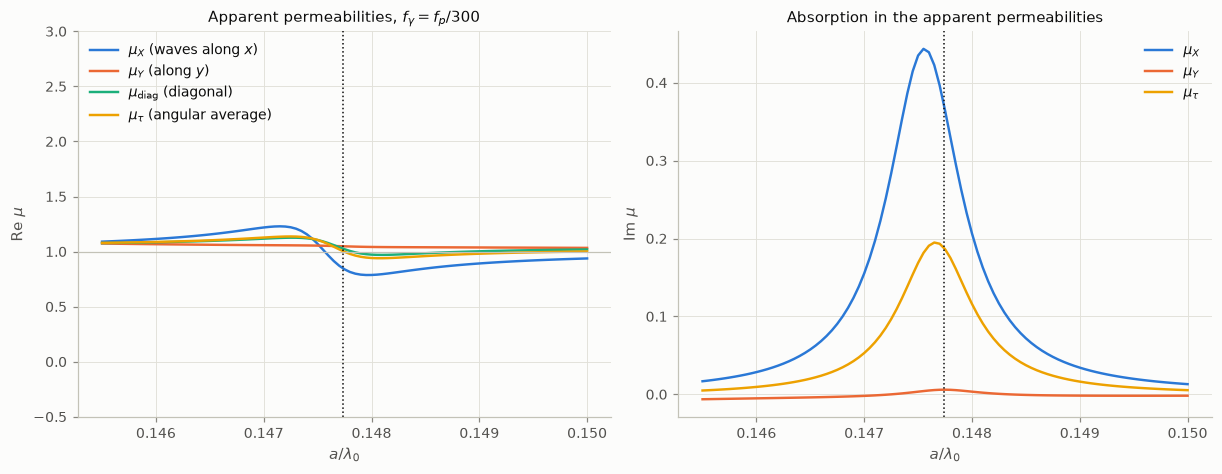

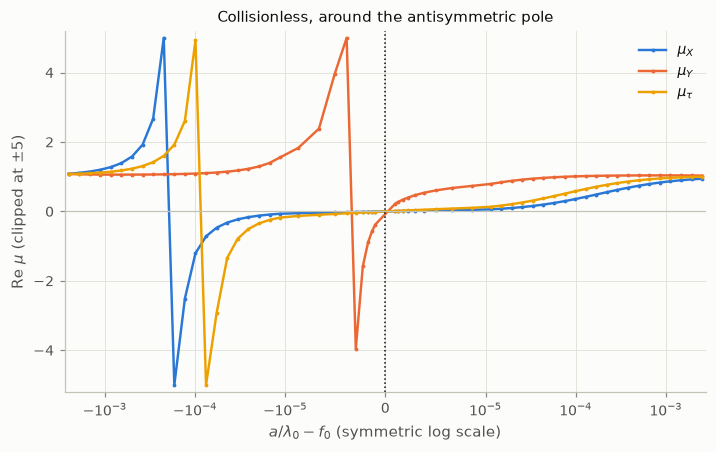

collisionless, Re mu on the grid around the pole: smallest Re mu_X -14.43, smallest Re mu_tau -30.53, smallest Re mu_Y -3.96


collisionless band with mu < 0 below the pole: along x 1.81e-04, along y 3.72e-06 (ratio 0.021, equal to the ratio of the residues to first order)


In [16]:
# --- permeabilities with loss
f_fine = np.arange(0.1455, 0.1500, 5e-5)
f_coarse = np.linspace(0.03, 0.19, 81)
t0 = time.time()
S_fine = scan_lattice(f_fine, FG)
S_coarse = scan_lattice(f_coarse, FG)
print(f"lossy scans ({len(f_fine)} + {len(f_coarse)} frequencies): {time.time() - t0:.0f} s")


def mu_set(f, S):
    k2 = (TWO_PI * f) ** 2
    cx_, cy_, cd_ = (np.array([cT_phi(a, p) for a in S[:, :5]]) for p in (0.0, np.pi / 2, np.pi / 4))
    tau_ = 0.25 * (cx_ + cy_ + 2 * cd_)
    return {nm: 1 / (1 - k2 * c) for nm, c in (("X", cx_), ("Y", cy_), ("D", cd_), ("tau", tau_))}


MU_f = mu_set(f_fine, S_fine)
MU_c = mu_set(f_coarse, S_coarse)
MU_0 = mu_set(f_wide, S0)

# frequency of the strongest response: the largest Im mu_X
ir = np.argmax(MU_f["X"].imag)
F_RES = f_fine[ir]
print(f"loss f_gamma = f_p/300: Im mu_X peaks at f = {F_RES:.5f} (lattice pole at {F_A_LAT:.5f})")
print(f"{'':10s} {'mu_X':>20s} {'mu_Y':>20s} {'mu_diag':>20s} {'mu_tau':>20s}")
print(f"{'at the peak':10s} " + " ".join(f"{MU_f[k][ir].real:9.4f}{MU_f[k][ir].imag:+9.4f}j" for k in ("X", "Y", "D", "tau")))
i_off = np.argmin(np.abs(f_coarse - 0.06))
print(f"{'f = 0.06':10s} " + " ".join(f"{MU_c[k][i_off].real:9.5f}{MU_c[k][i_off].imag:+9.5f}j" for k in ("X", "Y", "D", "tau")))
dmu = (MU_f["X"][ir] - MU_f["Y"][ir]) / (MU_f["tau"][ir] - 1)
dmu_off = (MU_c["X"][i_off] - MU_c["Y"][i_off]) / (MU_c["tau"][i_off] - 1)
print(f"(mu_X - mu_Y) / (mu_tau - 1): at the peak {dmu.real:+.3f}{dmu.imag:+.3f}j (modulus {abs(dmu):.3f}); at f = 0.06 {dmu_off.real:+.3f}{dmu_off.imag:+.3f}j (modulus {abs(dmu_off):.3f})")
print(f"smallest Re mu over the fine grid: X {MU_f['X'].real.min():.3f}, Y {MU_f['Y'].real.min():.3f}, diag {MU_f['D'].real.min():.3f}, tau {MU_f['tau'].real.min():.3f}; largest Re mu_X {MU_f['X'].real.max():.3f}")

# collisionless: band where mu_X < 0 just below the pole, from the condition k0^2 c_T = 1
xX = lambda f: (TWO_PI * f) ** 2 * cT_phi(lattice_point(f)[0], 0.0).real
f1 = brentq(lambda f: xX(f) - 1, f0 - 2e-3, f0 - 1e-7, xtol=1e-12)
xtau = lambda f: (TWO_PI * f) ** 2 * tau_a2_a4(lattice_point(f)[0])[0].real
f1t = brentq(lambda f: xtau(f) - 1, f0 - 2e-3, f0 - 1e-7, xtol=1e-12)
print(f"collisionless: mu_X < 0 between f = {f1:.6f} and the pole {f0:.6f} (width {f0 - f1:.2e}, {100 * (f0 - f1) / f0:.3f} % of f_0); mu_tau < 0 over a width {f0 - f1t:.2e}")
assert MU_f["X"].real.min() > 0, "with loss mu_X does not become negative"
assert abs(MU_f["X"][ir] - 1) > 5 * abs(MU_f["Y"][ir] - 1), "mu_Y hardly sees the resonance"
assert abs(dmu) > 1.0 and 0.1 < abs(dmu_off) < 1.0

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axs[0]
for k, col, lab in (("X", CAT[0], r"$\mu_X$ (waves along $x$)"), ("Y", CAT[1], r"$\mu_Y$ (along $y$)"), ("D", CAT[2], r"$\mu_{\rm diag}$ (diagonal)"), ("tau", CAT[3], r"$\mu_\tau$ (angular average)")):
    ax.plot(f_fine, MU_f[k].real, color=col, label=lab)
ax.axhline(1, color=AXIS, lw=0.8); ax.axvline(F_A_LAT, color=INK, ls=":", lw=1)
ax.set(xlabel=r"$a/\lambda_0$", ylabel=r"Re $\mu$", title=r"Apparent permeabilities, $f_\gamma=f_p/300$", ylim=(-0.5, 3.0))
ax.legend(loc="upper left")
ax = axs[1]
for k, col, lab in (("X", CAT[0], r"$\mu_X$"), ("Y", CAT[1], r"$\mu_Y$"), ("tau", CAT[3], r"$\mu_\tau$")):
    ax.plot(f_fine, MU_f[k].imag, color=col, label=lab)
ax.axvline(F_A_LAT, color=INK, ls=":", lw=1)
ax.set(xlabel=r"$a/\lambda_0$", ylabel=r"Im $\mu$", title="Absorption in the apparent permeabilities"); ax.legend()
plt.show()

offs = np.concatenate([-np.logspace(-2.6, -6, 30), np.logspace(-6, -2.6, 30)])
S_off = scan_lattice(f0 + offs, 0.0)
MU_off = mu_set(f0 + offs, S_off)
fig, ax = plt.subplots(figsize=(6.4, 4.0))
for k, col, lab in (("X", CAT[0], r"$\mu_X$"), ("Y", CAT[1], r"$\mu_Y$"), ("tau", CAT[3], r"$\mu_\tau$")):
    ax.plot(offs, np.clip(MU_off[k].real, -5, 5), ".-", color=col, ms=3, label=lab)
ax.axvline(0, color=INK, ls=":", lw=1); ax.axhline(0, color=AXIS, lw=0.8)
ax.set_xscale("symlog", linthresh=1e-5)
ax.set(xlabel=r"$a/\lambda_0-f_0$ (symmetric log scale)", ylabel=r"Re $\mu$ (clipped at $\pm5$)", title="Collisionless, around the antisymmetric pole", ylim=(-5.2, 5.2)); ax.legend()
plt.show()
print(f"collisionless, Re mu on the grid around the pole: smallest Re mu_X {MU_off['X'].real.min():.2f}, smallest Re mu_tau {MU_off['tau'].real.min():.2f}, smallest Re mu_Y {MU_off['Y'].real.min():.2f}")
xY = lambda f: (TWO_PI * f) ** 2 * cT_phi(lattice_point(f)[0], np.pi / 2).real
f1Y = brentq(lambda f: xY(f) - 1, f0 - 1e-4, f0 - 1e-7, xtol=1e-14)
print(f"collisionless band with mu < 0 below the pole: along x {f0 - f1:.2e}, along y {f0 - f1Y:.2e} (ratio {(f0 - f1Y) / (f0 - f1):.3f}, equal to the ratio of the residues to first order)")
assert MU_off["X"].real.min() < 0 and (f0 - f1Y) < 0.05 * (f0 - f1)

### 3.3 What the numbers say

The first printed table gives the apparent permeabilities at the peak of the absorption of $\mu_X$ (the frequency a little below the pole at which $k_0^2c_T=1$, where $\mu_X$ itself has its resonance; the pole is a pole of $c_T$ and the resonance of $\mu=1/(1-k_0^2c_T)$ is shifted from it by about the residue). Four statements, each with its number printed in the cell above.

1. **Direction dependence.** $\mu_X$ carries the resonance and $\mu_Y$ hardly sees it (the assertion in the cell requires the deviation of $\mu_Y$ from one to be much smaller than that of $\mu_X$), $\mu_{\rm diag}$ and $\mu_\tau$ lie in between. A permeability would give one number for all directions.
2. **Size of the non-magnetic part.** Since $\mu_{zz}$ is a single coefficient, $\mu_X-\mu_Y$ is made of the non-magnetic second-order terms. Its size compared with $\mu_\tau-1$, the permeability in the convention of section 1, is the printed ratio: at the resonance the difference between the two directions is *larger* than the permeability itself, and even at $f=0.06$, where everything is small, it is a sizable fraction of it. This is the quantitative form of the statement that for this structure the apparent permeability along a symmetry axis is as much a quadrupole and electric-dispersion effect as a magnetic one.
3. **Which parts are magnetic.** $\mu_\tau$ is the largest candidate for a permeability, and section 3.2 shows that it contains the quadrupole share printed there; $\mu_{\rm diag}$ avoids the quadrupole coupling of this mode and is the closest to a magnetic number, but it too carries whatever electric dispersion contributes at $45^\circ$ (it is a different combination of the same five coefficients, not a separate measurement of $\mu_{zz}$).
4. **Negative $\mu$.** Without loss $\mu_X<0$ in a band just below the pole whose width is the printed number (a small fraction of a percent of the frequency, about the residue $R_x$), and along $y$ in a band that is narrower by about the ratio of the residues. With bulk-silver loss the band is gone: $\mathrm{Re}\,\mu_X$ stays positive (the printed minimum), presumably because the loss broadens the resonance by more than the residue ($f_\gamma=f_p/300$ is about $8\times10^{-4}$ in $a/\lambda_0$ units, against a collisionless band width of $1.81\times10^{-4}$; the lossy linewidth itself is not printed). The figure of merit for negative $\mu$ of this sparse structure is therefore poor; the last cell of the section prints the residue for three sizes of the dimer.

### 3.4 Static limit

At low frequency the lattice of metal rods is a perfect-conductor array in the electrostatic limit. Two checks of the pipeline in a limit where the answer is known without scattering theory. (i) A *single* rod per cell with the huge negative permittivity of the metal at very low frequency reproduces Rayleigh's series for the square array (the formula used in notebook 03). (ii) For the dimer lattice a plane-wave expansion with the inverse rule (the $H_z$ formulation of `spec_basis` check g) does not converge for rods with negative permittivity (printed below: the sequence is not monotonic and jumps by tens of percent, presumably because the truncated operator has near-singular modes), so the independent value for the dimer is obtained with rods of *positive* permittivity, 4: the same geometry, the same code path, the plane-wave value extrapolated in $1/(2n+1)$ to infinite order.

In [17]:
# (i) single rod per cell, huge negative permittivity, against Rayleigh's series
Rr_, f_st = 0.3, 0.002
eta = np.pi * Rr_**2
eps_st = drude(f_st)
b_ = (eps_st - 1) / (eps_st + 1)
rayleigh = 1 + 2 * eta / (1 / b_ - eta - 0.305827 * b_ * eta**4 - 0.013362 * b_ * eta**8)
e_one = bl.driven(TWO_PI * f_st, (2e-3, 1e-3), [bl.Rod((0.0, 0.0), Rr_, eps_st)], "TE", M=6)[0]
check(f"(i) one rod of radius 0.3, eps = {eps_st:.0f}, f = {f_st}: eps_T of the lattice against Rayleigh's series (relative)", e_one[0, 0].real / rayleigh - 1, 2e-4)


# (ii) plane waves, TE, H_z formulation with the inverse rule
def pw_gvecs(n):
    m = np.arange(-n, n + 1)
    M1, M2 = np.meshgrid(m, m, indexing="ij")
    return 2 * np.pi * np.stack([M1.ravel(), M2.ravel()], 1)


def pw_fourier(rods, D, key):
    g = np.hypot(D[..., 0], D[..., 1])
    out = np.where(g < 1e-12, 1.0, 0.0).astype(complex)
    for r in rods:
        x = g * r.radius
        xs = np.where(x < 1e-9, 1.0, x)
        form = np.where(x < 1e-9, 1.0, 2 * jv(1, xs) / xs)
        out = out + (getattr(r, key) - 1) * np.pi * r.radius**2 * form * np.exp(-1j * (D @ np.asarray(r.center)))
    return out


def pw_tensor_te(rods, k0, kv, n):
    """eps_ij(w, k) of the TE problem by plane waves (inverse rule for 1/eps): E_0 from Faraday-free averages, D from the averaged Ampere law."""
    G = pw_gvecs(n); i0 = len(G) // 2
    E = pw_fourier(rods, G[:, None, :] - G[None, :, :], "eps")
    X = np.linalg.inv(E)
    k = np.asarray(kv, float); kg = k[None, :] + G; kn = np.hypot(*k)
    Lop = (kg @ kg.T) * X - k0**2 * np.eye(len(G))
    Es, Ds = [], []
    for J0 in (k / kn, np.array([-k[1], k[0]]) / kn):
        cross = kg[:, 0] * J0[1] - kg[:, 1] * J0[0]
        u = np.linalg.solve(Lop, 1j * cross * X[:, i0])
        F = 1j * np.stack([kg[:, 1], -kg[:, 0]], 1) * u[:, None]
        F[i0] -= J0
        E0 = (1j / k0) * (X[i0] @ F)
        Es.append(E0); Ds.append((kn**2 * E0 - k * (k @ E0) - 1j * k0 * J0) / k0**2)
    return np.array(Ds).T @ np.linalg.inv(np.array(Es).T)


f_pw, kv_pw = 0.05, (0.01, 0.0)
rods_diel = dimer(R0, R0, GAP, 4.0)
ms_d = bl.driven(TWO_PI * f_pw, kv_pw, rods_diel, "TE", M=M_LAT)[0]
ns = (8, 12, 16)
pw_vals = [pw_tensor_te(rods_diel, TWO_PI * f_pw, kv_pw, n) for n in ns]
x_ = 1 / (2 * np.array(ns) + 1.0)
extrap = (pw_vals[2] * x_[1] - pw_vals[1] * x_[2]) / (x_[1] - x_[2])
print("(ii) dimer with positive-permittivity rods (eps = 4), f = 0.05, kappa = 0.01 along x: eps_xx, eps_yy")
print(f"     multiple scattering {ms_d[0, 0].real:.5f} {ms_d[1, 1].real:.5f}; plane waves n = {ns}: " + "; ".join(f"{v[0, 0].real:.5f} {v[1, 1].real:.5f}" for v in pw_vals) + f"; extrapolated {extrap[0, 0].real:.5f} {extrap[1, 1].real:.5f}")
check("(ii) static eps of the dimer lattice (rods eps = 4): multiple scattering against extrapolated plane waves (relative to the largest element)", np.abs(extrap - ms_d).max() / np.abs(ms_d).max(), 1e-2)
rods_met = dimer(R0, R0, GAP, drude(0.1))
ms_m = bl.driven(TWO_PI * 0.1, kv_pw, rods_met, "TE", M=M_LAT)[0]
seq = [np.abs(pw_tensor_te(rods_met, TWO_PI * 0.1, kv_pw, n) - ms_m).max() / np.abs(ms_m).max() for n in (6, 10, 14, 18)]
print("     for the metal (eps = -5.25 at f = 0.1) the plane-wave expansion does not converge: relative difference from multiple scattering for n = 6, 10, 14, 18: " + ", ".join(f"{s:.3f}" for s in seq))
assert min(seq) > 1e-2

PASS  (i) one rod of radius 0.3, eps = -15624, f = 0.002: eps_T of the lattice against Rayleigh's series (relative): got -2.59865e-05, target 0, |diff| 2.60e-05 <= 2e-04


(ii) dimer with positive-permittivity rods (eps = 4), f = 0.05, kappa = 0.01 along x: eps_xx, eps_yy
     multiple scattering 1.21523 1.16426; plane waves n = (8, 12, 16): 1.23870 1.17655; 1.23026 1.17285; 1.22672 1.17089; extrapolated 1.21566 1.16474
PASS  (ii) static eps of the dimer lattice (rods eps = 4): multiple scattering against extrapolated plane waves (relative to the largest element): got 0.000400487, target 0, |diff| 4.00e-04 <= 1e-02


     for the metal (eps = -5.25 at f = 0.1) the plane-wave expansion does not converge: relative difference from multiple scattering for n = 6, 10, 14, 18: 0.378, 0.415, 0.026, 0.034


Both checks pass (the two numbers are printed): the single-rod value reproduces Rayleigh's series with the permittivity of the metal at very low frequency, and the dimer with dielectric rods agrees with the extrapolated plane waves. For the metal dimer itself there is no independent static value in this notebook; what supports the metal path is the single-rod check and the dispersion condition of section 3.1, which uses the metal response at finite frequency and is independent of the plane waves.

In [18]:
# the residue of the antisymmetric pole against the size, g / r fixed (the choice of r = 0.15); every Bloch mode in the window is listed
print("residues of the poles in k0^2 c_T, lattice Bloch modes at kB = (0.01, 0) between 0.13 and 0.165 (g / r = 0.4, f_p = 0.25)")
print(f"{'r':>6s} {'gap':>6s} {'gap to next cell':>16s} {'f (lattice)':>12s} {'R_x':>11s} {'R_y/R_x':>8s} {'R_45/R_x':>9s}")
Rsize, Rsize_all = {}, {}
for r_ in (0.10, 0.15, 0.20):
    g_ = 0.4 * r_
    rf = lambda f, r_=r_, g_=g_: dimer(r_, r_, g_, drude(f))
    bm = bloch_modes((0.01, 0.0), rf, fr=(0.13, 0.165), n=60)
    rows_m = []
    for fm in bm:
        Rm = []
        for phi in (0.0, np.pi / 2, np.pi / 4):
            v = []
            for s_ in (-1, 1):
                f = fm + s_ * 2e-5
                A_ = lattice_point(f, 0.0, rods=rf(f))[0]
                v.append((TWO_PI * f) ** 2 * cT_phi(A_, phi).real * (fm - f))
            Rm.append(np.mean(v))
        rows_m.append((fm, Rm[0], Rm[1] / Rm[0], Rm[2] / Rm[0]))
        print(f"{r_:6.2f} {g_:6.3f} {1 - 4 * r_ - g_:16.3f} {fm:12.6f} {Rm[0]:11.3e} {Rm[1] / Rm[0]:8.3f} {Rm[2] / Rm[0]:9.3f}")
    Rsize_all[r_] = rows_m
    cont = next(row for row in rows_m if row[1] > 1e-5)        # the lowest mode with a sizable residue: the continuation of the antisymmetric mode
    Rsize[r_] = (cont[0], cont[1], cont[2])
print("followed by continuity (lowest mode with R_x > 1e-5; frequency, small R_y/R_x and R_45/R_x of the smaller sizes): R_x = " + ", ".join(f"r = {r_}: {Rsize[r_][1]:.2e}" for r_ in Rsize))
hyb = max(Rsize_all[0.20], key=lambda row: row[1])
print(f"the strongest residue at r = 0.20 belongs to a different mode: f = {hyb[0]:.6f}, R_x = {hyb[1]:.2e}, R_y/R_x = {hyb[2]:.3f} (the continuation has f = {Rsize[0.20][0]:.6f}, R_x = {Rsize[0.20][1]:.2e}, R_y/R_x = {Rsize[0.20][2]:.3f})")
assert Rsize[0.15][1] > 3 * Rsize[0.10][1] > 0                      # like for like: the residue grows from r = 0.10 to 0.15
assert Rsize[0.20][1] < Rsize[0.15][1]                              # but not monotonically for the continued mode
assert hyb[0] != Rsize[0.20][0] and hyb[1] > Rsize[0.15][1]
assert max(Rsize[r_][2] for r_ in Rsize) < 0.06 < hyb[2]            # the continuation keeps the small R_y/R_x of the smaller sizes; the strongest one does not
print(f"time in section 3: {time.time() - T_START:.0f} s since the start of the notebook")

residues of the poles in k0^2 c_T, lattice Bloch modes at kB = (0.01, 0) between 0.13 and 0.165 (g / r = 0.4, f_p = 0.25)
     r    gap gap to next cell  f (lattice)         R_x  R_y/R_x  R_45/R_x


  0.10  0.040            0.560     0.148667   4.592e-05    0.017     0.318


  0.10  0.040            0.560     0.151474  -2.417e-09   -0.830     0.034


  0.15  0.060            0.340     0.147738   1.793e-04    0.020     0.325


  0.15  0.060            0.340     0.153794  -2.977e-09   -0.262     0.091


  0.20  0.080            0.120     0.144258   7.933e-05    0.048     0.371


  0.20  0.080            0.120     0.156118  -3.117e-07    0.127     0.448


  0.20  0.080            0.120     0.157971   2.690e-03    0.135     0.468


  0.20  0.080            0.120     0.163600  -4.599e-08   -0.027     0.304
followed by continuity (lowest mode with R_x > 1e-5; frequency, small R_y/R_x and R_45/R_x of the smaller sizes): R_x = r = 0.1: 4.59e-05, r = 0.15: 1.79e-04, r = 0.2: 7.93e-05
the strongest residue at r = 0.20 belongs to a different mode: f = 0.157971, R_x = 2.69e-03, R_y/R_x = 0.135 (the continuation has f = 0.144258, R_x = 7.93e-05, R_y/R_x = 0.048)
time in section 3: 57 s since the start of the notebook


**The size dependence, read with care.** Like for like, that is following the antisymmetric mode from $r=0.10$ to $r=0.15$ (similar frequency, small $R_y/R_x$ and $R_{45}/R_x$ of the same size), the residue grows by the printed factor, which is why $r=0.15$ was chosen over $r=0.10$. At $r=0.20$ the printed list has several modes with a sizable residue. The one that continues the smaller sizes is the lowest, and its residue is *smaller* than at $r=0.15$, so for like-for-like modes the residue is not monotonic in the size. The largest residue at $r=0.20$ belongs to a different mode, at a higher frequency and with a larger $R_y/R_x$; it is presumably a lattice hybrid (with a larger quadrupole part; its multipole content is not analyzed here). The step in $r$ also changes the coupling between dimers: the printed gap to the rod of the next cell, $1-4r-g$, falls from 0.34 at $r=0.15$ to 0.12 at $r=0.20$, comparable to the gap inside the dimer. So the size scan supports the choice of $r=0.15$ and nothing more; it is not a scaling law.

## 4. Unequal rods: first-order terms

Make the two rods different, $r_1=r+\delta/2$ and $r_2=r-\delta/2$ at fixed gap, with $r=0.15$ and $\delta=0.02$ (rods of radius 0.16 and 0.14). Now only the mirror $y\to-y$ is left, and section 1 says that exactly one first-order coefficient survives, $\varepsilon_{xy}=-\varepsilon_{yx}=g\,k_y$. For $\mathbf k=\kappa\hat y$ the Taylor coefficient of $\kappa^1$ is the matrix with $g$ and $-g$ off the diagonal. Three things are checked before the coefficient is used: it has the form the mirror and reciprocity demand; it is purely imaginary for lossless rods (the tensor is Hermitian at real $\mathbf k$, and $g$ multiplies the real $k_y$); and it is the same on both sides of $\delta=0$ in the sense of vanishing there.

In [19]:
DELTA = 0.02


def asym_rods(f, fg, delta=DELTA):
    return dimer(R0 + delta / 2, R0 - delta / 2, GAP, drude(f, fg))


print("smallest gap in the unequal-rod lattice:", round(bl.check_rods(asym_rods(0.14, 0.0)), 4))
print("(a) form of the first-order tensor gamma_ijl (coefficient of kappa along x and along y), f = 0.14, collisionless, M = 10")
cx1 = taylor_tensor(0.14, 0.0, 0.0, rods=asym_rods(0.14, 0.0))
cy1 = taylor_tensor(0.14, 0.0, np.pi / 2, rods=asym_rods(0.14, 0.0))
gam = np.zeros((2, 2, 2), complex); gam[:, :, 0], gam[:, :, 1] = cx1[1], cy1[1]
G_mir = np.mean([rep3(g_) for g_ in GROUPS["mirror y->-y (unequal rods)"]], axis=0)
G_c2v = np.mean([rep3(g_) for g_ in GROUPS["C2v (symmetric dimer)"]], axis=0)
gv = gam.ravel()
print("    gamma_ij,x (along x):", np.round(cx1[1], 8).tolist(), "\n    gamma_ij,y (along y):", np.round(cy1[1], 8).tolist())
check("(a) gamma is invariant under the mirror y -> -y (relative residual)", np.abs(G_mir @ gv - gv).max() / np.abs(gv).max(), 1e-5)
check("(a) gamma is antisymmetric in ij, as reciprocity requires (relative)", np.abs(gam + gam.transpose(1, 0, 2)).max() / np.abs(gv).max(), 1e-5)
check("(a) the part of gamma that C2v would allow vanishes (relative): the symmetric dimer has no first order", np.abs(G_c2v @ gv).max() / np.abs(gv).max(), 1e-5)
check("(a) first order along x vanishes (relative to along y)", np.abs(cx1[1]).max() / np.abs(cy1[1]).max(), 1e-5)
check("(a) the diagonal elements of the first-order matrix along y vanish (relative)", max(abs(cy1[1][0, 0]), abs(cy1[1][1, 1])) / abs(cy1[1][0, 1]), 1e-5)
check("(a) lossless: g is purely imaginary (|Re g| / |g|)", abs(cy1[1][0, 1].real) / abs(cy1[1][0, 1]), 1e-5)
g_sym = taylor_tensor(0.14, 0.0, np.pi / 2)[1]
print(f"    |g| = {abs(cy1[1][0, 1]):.4f} a for delta = {DELTA}; the symmetric dimer at the same frequency: {np.abs(g_sym).max():.1e}")

k_c = (0.31 - 0.12j, -0.22 + 0.17j)                                    # a complex wave vector, no relation to a mode
e_c = bl.driven(TWO_PI * 0.14, k_c, asym_rods(0.14, 0.0), "TE", M=M_LAT)[0]
e_cm = bl.driven(TWO_PI * 0.14, (-k_c[0], -k_c[1]), asym_rods(0.14, 0.0), "TE", M=M_LAT)[0]
check("(a) reciprocity eps(k) = eps(-k)^T for the unequal rods at a complex k (max difference)", np.abs(e_c - e_cm.T).max(), 1e-8)
k_r = (0.31, -0.22)
e_r = bl.driven(TWO_PI * 0.14, k_r, asym_rods(0.14, 0.0), "TE", M=M_LAT)[0]
e_ry = bl.driven(TWO_PI * 0.14, (k_r[0], -k_r[1]), asym_rods(0.14, 0.0), "TE", M=M_LAT)[0]
check("(a) the mirror: eps_xy(kx, ky) = -eps_xy(kx, -ky) for the unequal rods (max difference)", abs(e_r[0, 1] + e_ry[0, 1]), 1e-8)
check("(a) lossless, real k: eps is Hermitian (max |eps - eps^+|)", np.abs(e_r - e_r.conj().T).max(), 1e-8)
assert abs(e_r[0, 1].imag) > 1e-3 and abs(e_r[0, 1].real - e_r[1, 0].real) < 1e-8

smallest gap in the unequal-rod lattice: 0.06
(a) form of the first-order tensor gamma_ijl (coefficient of kappa along x and along y), f = 0.14, collisionless, M = 10
    gamma_ij,x (along x): [[(2e-08+2e-08j), -0j], [(-0+0j), 0j]] 
    gamma_ij,y (along y): [[(2e-08+1e-08j), 0.05508733j], [(-0-0.05508733j), (-0+0j)]]
PASS  (a) gamma is invariant under the mirror y -> -y (relative residual): got 4.70018e-07, target 0, |diff| 4.70e-07 <= 1e-05
PASS  (a) gamma is antisymmetric in ij, as reciprocity requires (relative): got 9.40035e-07, target 0, |diff| 9.40e-07 <= 1e-05
PASS  (a) the part of gamma that C2v would allow vanishes (relative): the symmetric dimer has no first order: got 0, target 0, |diff| 0.00e+00 <= 1e-05
PASS  (a) first order along x vanishes (relative to along y): got 4.5506e-07, target 0, |diff| 4.55e-07 <= 1e-05
PASS  (a) the diagonal elements of the first-order matrix along y vanish (relative): got 4.70018e-07, target 0, |diff| 4.70e-07 <= 1e-05
PASS  (a) lossless: g i

### 4.1 The coefficient through the resonances

$g(f)$ from the Cauchy integral along $y$, for the collisionless rods and for bulk-silver loss. The Bloch frequency of the antisymmetric band of this lattice is also computed, near which the resonance of $g$ should lie: the dark mode has acquired an electric dipole (rods of unequal size no longer cancel it). Two nearby frequencies must be told apart. A mode with an electric dipole along $y$ has a pole of $\varepsilon_{yy}(\omega,0)$ at its transverse frequency $\omega_T$, and $\varepsilon_{yy}(\omega,0)$ vanishes at a higher, longitudinal frequency $\omega_L$; the Bloch frequency at small $\kappa_B$ is the longitudinal one, since a Bloch mode is a zero of the response (for $\mathbf k\parallel\hat y$ it requires $\varepsilon_{yy}=0$ as $\kappa\to0$). The cell locates both, $\omega_L$ as the zero of $\varepsilon_{yy}(\omega,0)$ and $\omega_T$ as its pole (the sign change of $1/\varepsilon_{yy}$), and checks that the zero is the Bloch frequency. $g$ is expected to have its pole at $\omega_T$ as well (section 4.4 tests this).

antisymmetric band of the unequal-rod lattice at Gamma: f = 0.1478344 (kappa along x), 0.1478344 (along y); symmetric lattice 0.1477384


eps_yy(omega, 0) of the unequal-rod lattice: zero omega_L = 0.1478344 (Bloch frequency 0.1478344), pole omega_T = 0.1477970; omega_L - omega_T = 3.74e-05
PASS  the Bloch frequency of the antisymmetric band is the zero of eps_yy(omega, 0): omega_L against F_A_ASYM: got 0.147834, target 0.147834, |diff| 9.09e-08 <= 1e-06


scans: 11 s
f_gamma = f_p/300: |g| peaks at f = 0.14800 with g = +0.0321+0.0433j a  (|g| = 0.0539 a); the band is at 0.14783
away from the resonances, f = 0.06: g = +4.34e-06-6.50e-04j a
the resonant (absorptive) part: Re g peaks at f = 0.14780 with +0.0399 a; Im g is dispersive there (it changes by 0.039 a across the line) on a background of the tails of the neighboring poles
collisionless first-order coefficient: poles of g (local maxima of |g| above 0.3 a on the grid) at f = [0.1365 0.1478 0.1648 0.1672 0.173  0.1735 0.175  0.1755 0.1768 0.1772
 0.1812 0.1848]
   of which the antisymmetric band (0.14783) is the one with the nearest pole at 0.14775; the lowest pole (the bonding mode, section 2) is at 0.13650


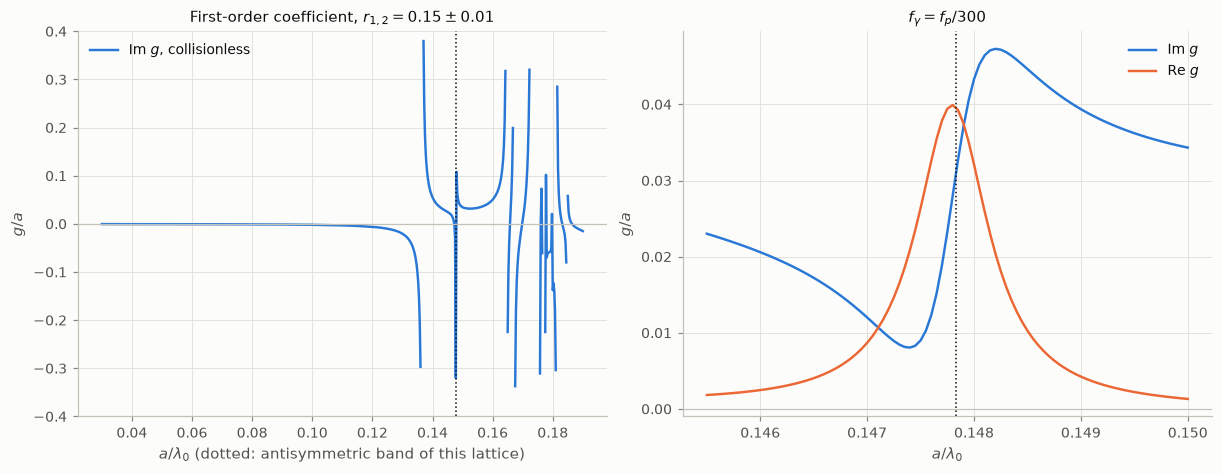

In [20]:
def g_point(f, fg, delta=DELTA, M=M_LAT):
    c = taylor_tensor(f, fg, np.pi / 2, rods=asym_rods(f, fg, delta), M=M)
    return c[1][0, 1], c[0][1, 1], c[2][0, 0]                        # g, eps_yy(0), alpha_xx;yy


t0 = time.time()
rods_a = lambda f: asym_rods(f, 0.0)
band_a = bloch_modes((0.02, 0.0), rods_a, fr=(0.1465, 0.1495), n=30)
band_a_y = bloch_modes((0.0, 0.02), rods_a, fr=(0.1465, 0.1495), n=30)
F_A_ASYM = band_a[0]
print(f"antisymmetric band of the unequal-rod lattice at Gamma: f = {F_A_ASYM:.7f} (kappa along x), {band_a_y[0]:.7f} (along y); symmetric lattice {F_A_LAT:.7f}")
eyy0 = lambda f: g_point(f, 0.0)[1].real                                        # eps_yy(omega, 0), collisionless
F_L = brentq(eyy0, F_A_ASYM - 2e-6, F_A_ASYM + 2e-6, xtol=1e-14)               # its zero: the longitudinal frequency
F_T = brentq(lambda f: 1 / eyy0(f), F_A_ASYM - 1e-4, F_A_ASYM - 2e-6, xtol=1e-14)   # its pole: the sign change of 1/eps_yy
print(f"eps_yy(omega, 0) of the unequal-rod lattice: zero omega_L = {F_L:.7f} (Bloch frequency {F_A_ASYM:.7f}), pole omega_T = {F_T:.7f}; omega_L - omega_T = {F_L - F_T:.2e}")
check("the Bloch frequency of the antisymmetric band is the zero of eps_yy(omega, 0): omega_L against F_A_ASYM", F_L, 1e-6, F_A_ASYM)
assert 0 < F_L - F_T < 1e-4 and abs(eyy0(F_T + 5e-7)) > 50          # a pole below the zero
f_g0 = np.unique(np.concatenate([np.linspace(0.03, 0.12, 19), np.linspace(0.12, 0.19, 281)]))
G0 = np.array([g_point(f, 0.0) for f in f_g0])
f_g_fine = np.arange(0.1455, 0.1500, 5e-5)
f_g_coarse = np.linspace(0.03, 0.19, 81)
G_fine = np.array([g_point(f, FG) for f in f_g_fine])
G_coarse = np.array([g_point(f, FG) for f in f_g_coarse])
print(f"scans: {time.time() - t0:.0f} s")
ig = np.argmax(np.abs(G_fine[:, 0]))
F_G = f_g_fine[ig]
g_max = G_fine[ig, 0]
print(f"f_gamma = f_p/300: |g| peaks at f = {F_G:.5f} with g = {g_max.real:+.4f}{g_max.imag:+.4f}j a  (|g| = {abs(g_max):.4f} a); the band is at {F_A_ASYM:.5f}")
i_lo = np.argmin(np.abs(f_g_coarse - 0.06))
print(f"away from the resonances, f = 0.06: g = {G_coarse[i_lo, 0].real:+.2e}{G_coarse[i_lo, 0].imag:+.2e}j a")
ireg = np.argmax(np.abs(G_fine[:, 0].real))
print(f"the resonant (absorptive) part: Re g peaks at f = {f_g_fine[ireg]:.5f} with {G_fine[ireg, 0].real:+.4f} a; Im g is dispersive there (it changes by {G_fine[:, 0].imag.max() - G_fine[:, 0].imag.min():.3f} a across the line) on a background of the tails of the neighboring poles")
ia = np.abs(G0[:, 0]); pk_ = find_peaks(ia, height=0.3)[0]
print("collisionless first-order coefficient: poles of g (local maxima of |g| above 0.3 a on the grid) at f =", np.round(f_g0[pk_], 4))
print(f"   of which the antisymmetric band ({F_A_ASYM:.5f}) is the one with the nearest pole at {f_g0[pk_][np.argmin(np.abs(f_g0[pk_] - F_A_ASYM))]:.5f}; the lowest pole (the bonding mode, section 2) is at {f_g0[pk_][0]:.5f}")
assert abs(F_G - F_A_ASYM) < 5e-4

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axs[0]
y_ = G0[:, 0].imag.copy(); y_[np.abs(y_) > 0.4] = np.nan
ax.plot(f_g0, y_, color=CAT[0], label=r"Im $g$, collisionless")
ax.axvline(F_A_ASYM, color=INK, ls=":", lw=1); ax.axhline(0, color=AXIS, lw=0.8)
ax.set(xlabel=r"$a/\lambda_0$ (dotted: antisymmetric band of this lattice)", ylabel=r"$g/a$", title=r"First-order coefficient, $r_{1,2}=0.15\pm0.01$", ylim=(-0.4, 0.4)); ax.legend()
ax = axs[1]
ax.plot(f_g_fine, G_fine[:, 0].imag, color=CAT[0], label=r"Im $g$"); ax.plot(f_g_fine, G_fine[:, 0].real, color=CAT[1], label=r"Re $g$")
ax.axvline(F_A_ASYM, color=INK, ls=":", lw=1); ax.axhline(0, color=AXIS, lw=0.8)
ax.set(xlabel=r"$a/\lambda_0$", ylabel=r"$g/a$", title=r"$f_\gamma=f_p/300$"); ax.legend()
plt.show()

**What the figure and the printed lines show.** In the lossy panel the real (absorptive) part of $g$ peaks at the band frequency and the imaginary part is dispersive there, so $g$ is resonant at the antisymmetric mode, as it should be if the mode now carries an electric dipole as well as a magnetic moment. More precisely the pole of $g$ is at $\omega_T$, below the Bloch frequency (the dotted line, $\omega_L$) by the printed split, which is smaller than the frequency step of the lossy scan, so the two cannot be told apart in the figure; section 4.4 shows that $g$, $\varepsilon_{yy}(\omega,0)$ and $\alpha_{xx;yy}$ change sign together at $\omega_T$, not at $\omega_L$. But the collisionless panel and the printed list of poles show that the antisymmetric band is only one of several poles of $g$: the lowest one is at the frequency of the bonding mode, and the background under the antisymmetric resonance in the lossy panel looks like the tail of that one. The first-order coefficient of this dimer is therefore not a property of the magnetic mode alone. The loss-limited maximum of $|g|$ is of the same order as its collisionless off-resonance value just above the bonding pole (the value at $f=0.14$ is printed in the check cell above).


### 4.2 Dependence on the difference of the radii

$g(\delta)$ at a fixed frequency, for $r_{1,2}=0.15\pm\delta/2$ (so the mean radius and the gap are fixed and the two rods differ in size). At $\delta=0$ the lattice is the symmetric one and $g$ must vanish; for small $\delta$ the response is linear if $g$ is a smooth function of the asymmetry that is odd under the exchange of the two rods (the exchange maps $\delta\to-\delta$ and $\varepsilon_{xy}\to-\varepsilon_{xy}$, by the mirror $x\to-x$ acting on the lattice). Two frequencies: the loss-limited peak, and one off resonance.

   delta                                peak             off resonance, f = 0.12
  0.0000  g = +5.700e-10j +7e-10, g/delta =    0.000  g = +3.224e-10j +2e-10, g/delta =    0.000
  0.0025  g = +5.724e-03j +4e-03, g/delta =    2.719  g = -7.735e-04j +3e-05, g/delta =    0.310
  0.0050  g = +1.142e-02j +7e-03, g/delta =    2.718  g = -1.546e-03j +5e-05, g/delta =    0.309
  0.0100  g = +2.264e-02j +1e-02, g/delta =    2.716  g = -3.088e-03j +1e-04, g/delta =    0.309
  0.0200  g = +4.331e-02j +3e-02, g/delta =    2.696  g = -6.138e-03j +2e-04, g/delta =    0.307
  0.0400  g = +6.116e-02j +7e-02, g/delta =    2.368  g = -1.198e-02j +4e-04, g/delta =    0.300
PASS  g vanishes at delta = 0 (peak), relative to g at delta = 0.01: got 3.34182e-08, target 0, |diff| 3.34e-08 <= 1e-05
PASS  g is linear in delta for small delta (peak): log-log slope between 0.0025 and 0.01: got 0.999321, target 1, |diff| 6.79e-04 <= 6e-02
PASS  g vanishes at delta = 0 (off resonance, f = 0.12), relative to g at del

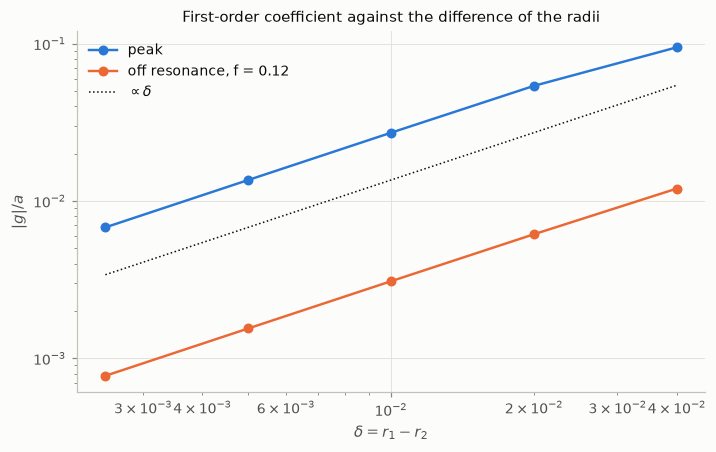

In [21]:
deltas = np.array([0.0, 0.0025, 0.005, 0.01, 0.02, 0.04])
g_delta = {}
for label, f_ in (("peak", F_G), ("off resonance, f = 0.12", 0.12)):
    g_delta[label] = np.array([g_point(f_, FG, d)[0] for d in deltas])
print(f"{'delta':>8s}  " + "  ".join(f"{k:>34s}" for k in g_delta))
for i, d in enumerate(deltas):
    print(f"{d:8.4f}  " + "  ".join(f"g = {g_delta[k][i].imag:+.3e}j {g_delta[k][i].real:+.0e}, g/delta = {abs(g_delta[k][i]) / d if d else 0:8.3f}" for k in g_delta))
for k, gd in g_delta.items():
    check(f"g vanishes at delta = 0 ({k}), relative to g at delta = 0.01", abs(gd[0]) / abs(gd[3]), 1e-5)
    slope = np.log(abs(gd[3] / gd[1])) / np.log(deltas[3] / deltas[1])
    check(f"g is linear in delta for small delta ({k}): log-log slope between 0.0025 and 0.01", slope, 0.06, 1.0)
for k, gd in g_delta.items():
    check(f"g/delta is constant for delta <= 0.01 ({k}): g(0.01)/0.01 against g(0.0025)/0.0025", abs(gd[3]) / 0.01 / (abs(gd[1]) / 0.0025), 5e-3, 1.0)
fig, ax = plt.subplots(figsize=(6.4, 4.0))
for (k, gd), col in zip(g_delta.items(), (CAT[0], CAT[1])):
    ax.loglog(deltas[1:], np.abs(gd[1:]), "o-", color=col, label=k)
dd = np.array([0.0025, 0.04]); ax.loglog(dd, 0.5 * np.abs(g_delta["peak"][1]) * dd / dd[0], color=INK, ls=":", lw=1, label=r"$\propto\delta$")
ax.set(xlabel=r"$\delta=r_1-r_2$", ylabel=r"$|g|/a$", title="First-order coefficient against the difference of the radii"); ax.legend()
plt.show()

The coefficient vanishes at $\delta=0$ (to the noise of the extraction) and is linear in $\delta$ over the printed range: $|g|/\delta$ is constant to a fraction of a percent for $\delta\le0.01$ at both frequencies (the checks assert the vanishing and the logarithmic slope), and bends away from it only at the largest $\delta$, where the rods differ by a quarter of the radius. So the first-order term goes to zero continuously as $r_1\to r_2$, with the slope printed in the $|g|/\delta$ column.


### 4.3 Which magnetoelectric coupling is it?

Notebook 01, section 1: for $\mathbf D=\varepsilon\mathbf E+\xi\mathbf H$, $\mathbf B=\zeta\mathbf E+\mu\mathbf H$ the single tensor is $\varepsilon_{\rm LL}=\varepsilon-\xi\mu^{-1}\zeta+(\xi\mu^{-1}K-K\mu^{-1}\zeta)/k_0+K^{\mathsf T}(1-\mu^{-1})K/k_0^2$, and its first-order term is the one above. For a reciprocal medium $\zeta=-\xi^{\mathsf T}$. In two dimensions with $\mathbf E$ in the plane and $\mathbf H=H_z\hat z$ only the couplings $\xi_{xz},\xi_{yz}$ (an electric polarization in the plane produced by $H_z$) and their partners $\zeta_{zx}=-\xi_{xz},\zeta_{zy}=-\xi_{yz}$ enter. Writing $K\mathbf v=\mathbf k\times\mathbf v$ and keeping the in-plane block, with $\mathbf w=\hat z\times\mathbf k$, one finds $\varepsilon^{(1)}_{ij}=(\xi_iw_j-w_i\xi_j)/(k_0\mu_{zz})$, so that

$$\varepsilon^{(1)}_{xy}=-\varepsilon^{(1)}_{yx}=\frac{\xi_{xz}k_x+\xi_{yz}k_y}{k_0\,\mu_{zz}} .$$

The mirror $y\to-y$ allows $\xi_{yz}$ (the polarization along $y$ is odd, and so is $H_z$) and forbids $\xi_{xz}$ (even polarization, odd $H_z$). The cell checks the formula on random media with the notebook-01 function, and shows that the partner relation matters: with $\zeta=+\xi^{\mathsf T}$ the first-order term would be symmetric in $ij$, which reciprocity forbids.

In [22]:
def cross_matrix(k):
    return np.array([[0, -k[2], k[1]], [k[2], 0, -k[0]], [-k[1], k[0], 0]])


def eps_LL(eps, mu, xi, zeta, k, k0=1.0):
    K, mi = cross_matrix(k), np.linalg.inv(mu)
    return eps - xi @ mi @ zeta + (xi @ mi @ K - K @ mi @ zeta) / k0 - K @ (np.eye(3) - mi) @ K / k0**2


worst, worst_sym = 0.0, 0.0
for trial in range(100):
    eps_m_ = np.diag([2 + rng.random(), 2 + rng.random(), 2 + rng.random()]) + 0.1 * rng.normal(size=(3, 3)); eps_m_ = 0.5 * (eps_m_ + eps_m_.T)
    mu_m_ = np.diag([1.2, 1.3, 1.5 + rng.random()])
    xi_m_ = np.zeros((3, 3)); xi_m_[0, 2], xi_m_[1, 2] = rng.normal(size=2)
    k_m_ = np.array([rng.normal(), rng.normal(), 0.0]); k0_ = 0.7 + rng.random()
    first = lambda zeta: 0.5 * (eps_LL(eps_m_, mu_m_, xi_m_, zeta, k_m_, k0_) - eps_LL(eps_m_, mu_m_, xi_m_, zeta, -k_m_, k0_))[:2, :2]
    s_ = (xi_m_[0, 2] * k_m_[0] + xi_m_[1, 2] * k_m_[1]) / (k0_ * mu_m_[2, 2])
    worst = max(worst, np.abs(first(-xi_m_.T) - np.array([[0, s_], [-s_, 0]])).max())
    f_sym = first(xi_m_.T)
    worst_sym = max(worst_sym, np.abs(f_sym - f_sym.T).max() - np.abs(f_sym + f_sym.T).max())
check("first-order term of eps_LL for zeta = -xi^T equals (xi_xz kx + xi_yz ky)/(k0 mu_zz) times the antisymmetric unit matrix (max difference, 100 media)", worst, 1e-12)
assert worst_sym <= 1e-12                                              # with zeta = +xi^T the first-order term is symmetric (not antisymmetric)
print("with zeta = +xi^T the first-order term is symmetric in ij, which reciprocity forbids: the partner relation is zeta = -xi^T")
k0_gl = TWO_PI * F_G
print(f"at the peak of |g| (f = {F_G:.5f}): xi_yz / mu_zz = g k0 = {(g_max * k0_gl).real:+.3e}{(g_max * k0_gl).imag:+.3e}j (units of 1/eta_0 = 1 in these units), xi_xz = 0 by the mirror")
print(f"collisionless, f = 0.14: xi_yz / mu_zz = {(taylor_tensor(0.14, 0.0, np.pi / 2, rods=asym_rods(0.14, 0.0))[1][0, 1] * TWO_PI * 0.14).imag:+.3e}j")

PASS  first-order term of eps_LL for zeta = -xi^T equals (xi_xz kx + xi_yz ky)/(k0 mu_zz) times the antisymmetric unit matrix (max difference, 100 media): got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-12
with zeta = +xi^T the first-order term is symmetric in ij, which reciprocity forbids: the partner relation is zeta = -xi^T
at the peak of |g| (f = 0.14800): xi_yz / mu_zz = g k0 = +2.986e-02+4.028e-02j (units of 1/eta_0 = 1 in these units), xi_xz = 0 by the mirror
collisionless, f = 0.14: xi_yz / mu_zz = +4.846e-02j


So the first-order coefficient of the unequal dimer is the coupling $\xi_{yz}$ (equivalently $\zeta_{zy}=-\xi_{yz}$), the one between $H_z$ and an electric polarization along $y$, and only that one: the Taylor coefficients show no other component (the checks above), and $\xi_{xz}$ is excluded by the mirror. In the dimer picture, which is a reading and not something computed: the antisymmetric mode, in which the two rods carry opposite currents along $y$ and which has a magnetic moment $m_z$, acquires a net electric dipole $p_y$ when one rod is larger than the other, so that $H_z$ drives $p_y$ and $E_y$ drives $m_z$. This is the Omega-type, reciprocal bianisotropy. The residue test of section 4.4 supports it: the antisymmetric pole appears in $\varepsilon_{yy}(\omega,0)$, that is, the mode acquires an electric dipole along $y$, when $\delta\ne0$. The size of $\xi_{yz}/\mu_{zz}=gk_0$ at the resonance and off it is printed; it is in units where the vacuum has $\varepsilon=\mu=1$.

### 4.4 What a first-order term does to bulk waves

**Waves along $x$.** The dispersion condition is $\det M(\mathbf k)=0$ with $M=k_0^2\varepsilon(\mathbf k)-(k^2I-\mathbf k\mathbf k^{\mathsf T})$. The matrix $k^2I-\mathbf k\mathbf k^{\mathsf T}$ is symmetric and even in $\mathbf k$, so reciprocity, $\varepsilon_{ij}(\mathbf k)=\varepsilon_{ji}(-\mathbf k)$, gives $M(\mathbf k)=M(-\mathbf k)^{\mathsf T}$ and therefore $\det M(\mathbf k)=\det M(-\mathbf k)$: every Bloch mode has $\omega(\mathbf k)=\omega(-\mathbf k)$, whatever the first-order coefficient. (The cell checks the determinant identity and the equality of the Bloch frequencies at $\pm\mathbf k_B$ for the unequal rods.) So a first-order term cannot make a reciprocal bulk wave propagate differently forward and backward. Along the dimer axis the mirror does more: it forces the first-order term to vanish identically (printed in the checks at the head of section 4), so for waves along $x$ the bianisotropy has no first-order effect on the bulk dispersion at all. What it does there is indirect: the antisymmetric mode, which is dark in the symmetric lattice, acquires an electric dipole along $y$ and appears as a pole of $\varepsilon_{yy}(\omega,0)$, with a strength that grows as $\delta^2$ (the residue table below), that is, as the square of $\xi_{yz}$. The difference of the reflection of waves incident on the two faces of a slab, the signature of bianisotropy, is a statement about interfaces and is not tested here: no slab of dimers is computed.

**Waves along $y$.** Here the first-order term couples the transverse field $E_x$ to the longitudinal one $E_y$. Eliminating $E_y$ from the $2\times2$ wave equation gives $\kappa^2=k_0^2\big[\varepsilon_{xx}(\kappa)-\varepsilon_{xy}\varepsilon_{yx}/\varepsilon_{yy}\big]$, and with $\varepsilon_{xy}=g\kappa=-\varepsilon_{yx}$ the apparent second-order coefficient seen by these waves is $\alpha_{xx;yy}+g^2/\varepsilon_{yy}(\omega,0)$. For lossless rods $g^2=-|g|^2$. **A retrieval along $y$ would attribute to the "permeability" this term, which is bianisotropic.** How large it is depends on the position relative to two frequencies (4.1): $\omega_T$, the pole of $\varepsilon_{yy}(\omega,0)$, and $\omega_L>\omega_T$, its zero, which is the Bloch frequency. Near $\omega_T$ a single mode makes the residue of the $2\times2$ tensor a rank-one matrix: $\varepsilon_{yy}\sim u_y^2$, $\varepsilon_{xy}\sim u_xu_y\kappa$, $\varepsilon_{xx}\sim-u_x^2\kappa^2$ (up to a common factor $1/(\omega_T-\omega)$), so that $g^2/(\varepsilon_{yy}\alpha_{xx;yy})\to-1$ and the pole of $\alpha_{xx;yy}$ cancels in $\alpha_{xx;yy}+g^2/\varepsilon_{yy}$. That is an expectation for one dominant mode; the cell tests it through the ratio printed at $\omega_T\pm5\times10^{-7}$. What the cancellation means is that, for waves along $y$, the bianisotropic term removes the pole of the dark mode from the coefficient; the resonance that those waves see moves to $\omega_L$, where $\varepsilon_{yy}\to0$ and $g^2/\varepsilon_{yy}$ diverges. The cell prints $\alpha_{xx;yy}$, $g^2/\varepsilon_{yy}$ and their sum through both frequencies, and the residue of $\varepsilon_{yy}$ and the split $\omega_L-\omega_T$ against $\delta$. With loss the pole and the zero are broadened; the relative size of the term at the loss-limited peak (printed, a few percent) is expected to be set by the split divided by the loss linewidth, which would make it grow as $\delta^2$, but that is not tested (the computed part is the dependence of the split on $\delta$). The cell also checks the Schur-complement identity on the computed tensor.

In [23]:
# reciprocity of the bulk dispersion, numerically, for the unequal rods
k_t = np.array([0.5, 0.3]); f_t = 0.13
Mdet = lambda f, k: np.linalg.det((TWO_PI * f) ** 2 * bl.driven(TWO_PI * f, k, asym_rods(f, 0.0), "TE", M=M_LAT)[0] - (k @ k * np.eye(2) - np.outer(k, k)))
dp, dm = Mdet(f_t, k_t), Mdet(f_t, -k_t)
check("det M(k) = det M(-k) for the unequal rods (relative difference, real k)", abs(dp - dm) / abs(dp), 1e-8)
kc = np.array([0.5 - 0.2j, 0.3 + 0.1j])
dpc, dmc = Mdet(f_t, kc), Mdet(f_t, -kc)
check("det M(k) = det M(-k) for the unequal rods (relative difference, complex k)", abs(dpc - dmc) / abs(dpc), 1e-8)
modes_p = bloch_modes((0.5, 0.3), rods_a, fr=(0.05, 0.17), n=200)
modes_m = bloch_modes((-0.5, -0.3), rods_a, fr=(0.05, 0.17), n=200)
print(f"Bloch frequencies of the unequal-rod lattice at +kB and -kB, kB = (0.5, 0.3): {len(modes_p)} and {len(modes_m)} modes below 0.17; lowest four {np.round(modes_p[:4], 7)} and {np.round(modes_m[:4], 7)}")
assert len(modes_p) == len(modes_m) and len(modes_p) >= 4
check("Bloch frequencies at kB and -kB agree (max difference)", np.abs(modes_p - modes_m).max(), 1e-9)
modes_x = bloch_modes((0.5, 0.0), rods_a, fr=(0.05, 0.17), n=200)
modes_mx = bloch_modes((-0.5, 0.0), rods_a, fr=(0.05, 0.17), n=200)
check("same along the dimer axis, kB = (+-0.5, 0) (max difference)", np.abs(modes_x - modes_mx).max(), 1e-9)

# the antisymmetric mode becomes visible in eps_yy(omega, 0) when the rods differ: residue against delta
print("antisymmetric band in eps_yy(omega, 0), collisionless: Bloch frequency f_0, zero omega_L, pole omega_T (sign change of 1/eps_yy); residue (omega_T - f) eps_yy at omega_T +- 5e-5, averaged")
dl = np.array([0.0025, 0.005, 0.01])
res_yy, res_bloch, splits = [], [], []
for d in dl:
    rf = lambda f, d=d: asym_rods(f, 0.0, d)
    f0d = bloch_modes((0.004, 0.0), rf, fr=(0.1465, 0.1495), n=30)
    assert len(f0d) == 1
    e0 = lambda f, rf=rf: taylor_tensor(f, 0.0, 0.0, rods=rf(f), orders=(0,))[0][1, 1].real
    fL_ = brentq(e0, f0d[0] - 3e-7, f0d[0] + 3e-7, xtol=1e-15)
    fT_ = brentq(lambda f: 1 / e0(f), fL_ - 1e-4, fL_ - 3e-9, xtol=1e-15)
    check(f"delta = {d}: the Bloch frequency is the zero of eps_yy(omega, 0) (f_0 against omega_L)", fL_, 1e-7, f0d[0])
    res_yy.append(np.mean([e0(fT_ + sgn * 5e-5) * (-sgn * 5e-5) for sgn in (-1, 1)]))
    res_bloch.append(np.mean([e0(f0d[0] + sgn * 5e-5) * (-sgn * 5e-5) for sgn in (-1, 1)]))      # the recipe about the wrong point, for comparison
    splits.append(fL_ - fT_)
    print(f"   delta = {d:.4f}: f_0 = {f0d[0]:.7f}, omega_L - omega_T = {splits[-1]:.2e}, residue about the pole {res_yy[-1]:.3e} (about the Bloch frequency {res_bloch[-1]:.3e}, {100 * (res_bloch[-1] / res_yy[-1] - 1):+.1f} %)")
slope2 = np.log(res_yy[2] / res_yy[0]) / np.log(dl[2] / dl[0])
slope_split = np.log(splits[2] / splits[0]) / np.log(dl[2] / dl[0])
slope_bloch = np.log(res_bloch[2] / res_bloch[0]) / np.log(dl[2] / dl[0])
print(f"log-log slopes between delta = 0.0025 and 0.01: residue about the pole {slope2:.3f} (about the Bloch frequency {slope_bloch:.3f}), split omega_L - omega_T {slope_split:.3f}")
check("the residue of the antisymmetric pole in eps_yy(omega, 0), taken about the pole, grows as delta^2: log-log slope between 0.0025 and 0.01", slope2, 0.15, 2.0)
check("the split omega_L - omega_T grows as delta^2: log-log slope between 0.0025 and 0.01", slope_split, 0.15, 2.0)
assert res_yy[0] > 0
eps_sym = taylor_tensor(F_A_LAT + 1e-4, 0.0, 0.0)[0][1, 1].real, taylor_tensor(F_A_LAT - 1e-4, 0.0, 0.0)[0][1, 1].real
print(f"symmetric lattice: eps_yy(omega, 0) at f_0 -+ 1e-4: {eps_sym[1]:.5f}, {eps_sym[0]:.5f}: no pole (the antisymmetric mode is dark at k = 0)")
assert abs(eps_sym[0] - eps_sym[1]) < 1e-2

# size of the bianisotropic contribution to the second-order coefficient along y, at the peak
gp, eyy, axxyy = g_point(F_G, FG)
k2 = (TWO_PI * F_G) ** 2
corr = gp**2 / eyy
print(f"at f = {F_G:.5f} (loss f_gamma = f_p/300): k0^2 alpha_xx;yy = {k2 * axxyy:.4f}; bianisotropic term k0^2 g^2 / eps_yy = {k2 * corr:.4f}; ratio {abs(corr / axxyy):.3f}")
mu_Y0, mu_Y1 = 1 / (1 - k2 * axxyy), 1 / (1 - k2 * (axxyy + corr))
print(f"apparent mu_Y without / with the g^2 term: {mu_Y0:.4f} / {mu_Y1:.4f}")
print(f"collisionless, unequal rods (delta = {DELTA}): omega_T = {F_T:.7f}, omega_L = {F_L:.7f}, split {F_L - F_T:.2e}; the coefficient seen by waves along y, alpha_xx;yy + g^2 / eps_yy, through both")
print(f"{'f - omega_L':>12s} {'f - omega_T':>12s} {'Im g':>9s} {'eps_yy(0)':>10s} {'alpha':>9s} {'g^2/eps_yy':>11s} {'alpha + g^2/eps':>16s} {'g^2/(eps alpha)':>16s}")
pts = sorted([F_L + o for o in (-3e-4, -1e-4, -5e-5, -4e-5, -3.5e-5, -3e-5, -1e-5, -2e-6, 2e-6)] + [F_T - 5e-7, F_T + 5e-7])
tab = {}
for fq in pts:
    gq, eq, aq = g_point(fq, 0.0)
    tab[fq] = (gq, eq, aq, aq + gq**2 / eq)
    print(f"{fq - F_L:+12.2e} {fq - F_T:+12.2e} {gq.imag:+9.3f} {eq.real:+10.3f} {aq.real:+9.4f} {(gq**2 / eq).real:+11.4f} {tab[fq][3].real:+16.4f} {(gq**2 / (eq * aq)).real:+16.3f}")
sgn_ = lambda x: np.sign(np.real(x))
tm, tp = tab[F_T - 5e-7], tab[F_T + 5e-7]
assert sgn_(tm[0] / 1j) != sgn_(tp[0] / 1j) and sgn_(tm[1]) != sgn_(tp[1]) and sgn_(tm[2]) != sgn_(tp[2])   # g, eps_yy and alpha change sign together at omega_T
for nm, tt in (("below", tm), ("above", tp)):
    check(f"g^2 / (eps_yy alpha_xx;yy) at omega_T, 5e-7 {nm} it: rank-one residue gives -1", (tt[0]**2 / (tt[1] * tt[2])).real, 5e-2, -1.0)
check("alpha + g^2/eps_yy is continuous through omega_T: |difference| over the mean |alpha| at omega_T +- 5e-7", abs(tp[3] - tm[3]) / (0.5 * (abs(tp[2]) + abs(tm[2]))), 5e-3)
ratios = {o: abs(tab[F_L + o][0]**2 / tab[F_L + o][1] / tab[F_L + o][2]) for o in (-4e-5, -3.5e-5, -3e-5, -1e-5, -2e-6)}
print("|g^2 / eps_yy| over |alpha_xx;yy| at omega_L -4e-5 (just below omega_T), -3.5e-5, -3e-5, -1e-5, -2e-6: " + ", ".join(f"{v:.2f}" for v in ratios.values()))
assert ratios[-4e-5] < 1 < ratios[-3.5e-5] < ratios[-3e-5] < ratios[-1e-5] < ratios[-2e-6]      # about 1 across the pole, growing toward omega_L
assert tab[F_L - 2e-6][3].real > 0 > tab[F_L + 2e-6][3].real and abs(tab[F_L - 2e-6][3]) > 5 * abs(tp[3])   # the coefficient diverges at omega_L, not at omega_T
ratio_1e5, ratio_2e6 = ratios[-1e-5], ratios[-2e-6]

# the Schur complement identity on the computed tensor
kap = 0.05
e_s = bl.driven(TWO_PI * F_G, (0.0, kap), asym_rods(F_G, FG), "TE", M=M_LAT)[0]
k02 = (TWO_PI * F_G) ** 2
Mm = k02 * e_s - np.diag([kap**2, 0.0])
schur = k02 * e_s[1, 1] * ((k02 * e_s[0, 0] - kap**2) - k02 * e_s[0, 1] * e_s[1, 0] / e_s[1, 1])
check("det M = k0^2 eps_yy [(k0^2 eps_xx - kappa^2) - k0^2 eps_xy eps_yx / eps_yy] on the computed tensor (relative)", abs(np.linalg.det(Mm) - schur) / abs(schur), 1e-10)
cg = taylor_tensor(0.14, 0.0, np.pi / 2, rods=asym_rods(0.14, 0.0))
check("the tensor elements are of the form eps_xy = g kappa, eps_yx = -g kappa at kappa = 0.05 (checked against the Taylor coefficient to third order)", abs(bl.driven(TWO_PI * 0.14, (0.0, 0.05), asym_rods(0.14, 0.0), "TE", M=M_LAT)[0][0, 1] - 0.05 * cg[1][0, 1] - 0.05**3 * cg[3][0, 1]), 1e-7)
print(f"total run time {time.time() - T_START:.0f} s")

PASS  det M(k) = det M(-k) for the unequal rods (relative difference, real k): got 1.86205e-10, target 0, |diff| 1.86e-10 <= 1e-08
PASS  det M(k) = det M(-k) for the unequal rods (relative difference, complex k): got 9.62424e-11, target 0, |diff| 9.62e-11 <= 1e-08


Bloch frequencies of the unequal-rod lattice at +kB and -kB, kB = (0.5, 0.3): 4 and 4 modes below 0.17; lowest four [0.0783705 0.1479025 0.1547028 0.1673822] and [0.0783705 0.1479025 0.1547028 0.1673822]
PASS  Bloch frequencies at kB and -kB agree (max difference): got 3.04479e-14, target 0, |diff| 3.04e-14 <= 1e-09


PASS  same along the dimer axis, kB = (+-0.5, 0) (max difference): got 8.40994e-15, target 0, |diff| 8.41e-15 <= 1e-09
antisymmetric band in eps_yy(omega, 0), collisionless: Bloch frequency f_0, zero omega_L, pole omega_T (sign change of 1/eps_yy); residue (omega_T - f) eps_yy at omega_T +- 5e-5, averaged


PASS  delta = 0.0025: the Bloch frequency is the zero of eps_yy(omega, 0) (f_0 against omega_L): got 0.14774, target 0.14774, |diff| 3.32e-09 <= 1e-07
   delta = 0.0025: f_0 = 0.1477399, omega_L - omega_T = 5.94e-07, residue about the pole 1.015e-06 (about the Bloch frequency 1.015e-06, +0.0 %)


PASS  delta = 0.005: the Bloch frequency is the zero of eps_yy(omega, 0) (f_0 against omega_L): got 0.147744, target 0.147744, |diff| 3.33e-09 <= 1e-07
   delta = 0.0050: f_0 = 0.1477444, omega_L - omega_T = 2.35e-06, residue about the pole 4.252e-06 (about the Bloch frequency 4.262e-06, +0.2 %)


PASS  delta = 0.01: the Bloch frequency is the zero of eps_yy(omega, 0) (f_0 against omega_L): got 0.147762, target 0.147762, |diff| 3.39e-09 <= 1e-07
   delta = 0.0100: f_0 = 0.1477624, omega_L - omega_T = 9.36e-06, residue about the pole 1.722e-05 (about the Bloch frequency 1.785e-05, +3.6 %)
log-log slopes between delta = 0.0025 and 0.01: residue about the pole 2.042 (about the Bloch frequency 2.068), split omega_L - omega_T 1.989
PASS  the residue of the antisymmetric pole in eps_yy(omega, 0), taken about the pole, grows as delta^2: log-log slope between 0.0025 and 0.01: got 2.04226, target 2, |diff| 4.23e-02 <= 1e-01
PASS  the split omega_L - omega_T grows as delta^2: log-log slope between 0.0025 and 0.01: got 1.98911, target 2, |diff| 1.09e-02 <= 1e-01
symmetric lattice: eps_yy(omega, 0) at f_0 -+ 1e-4: 1.84311, 1.84818: no pole (the antisymmetric mode is dark at k = 0)
at f = 0.14800 (loss f_gamma = f_p/300): k0^2 alpha_xx;yy = 0.0420+0.0035j; bianisotropic term k0^2 g^2 / eps_y

   -5.00e-05    -1.26e-05    -1.266     +7.365   +0.3583     -0.2176          +0.1407           -0.607
   -4.00e-05    -2.62e-06    -6.189    +28.317   +1.5148     -1.3525          +0.1623           -0.893
   -3.79e-05    -5.00e-07   -32.059   +138.424   +7.5930     -7.4246          +0.1683           -0.978
   -3.69e-05    +5.00e-07   +33.305   -139.776   -7.7645     +7.9359          +0.1714           -1.022
   -3.50e-05    +2.38e-06    +6.914    -27.451   -1.5638     +1.7415          +0.1777           -1.114
   -3.00e-05    +7.38e-06    +2.244     -7.571   -0.4665     +0.6648          +0.1983           -1.425
   -1.00e-05    +2.74e-05    +0.624     -0.680   -0.0862     +0.5735          +0.4873           -6.651
   -2.00e-06    +3.54e-05    +0.489     -0.105   -0.0546     +2.2767          +2.2221          -41.708
   +2.00e-06    +3.94e-05    +0.443     +0.095   -0.0436     -2.0715          -2.1151          +47.515
PASS  g^2 / (eps_yy alpha_xx;yy) at omega_T, 5e-7 below it: rank-one resi

PASS  the tensor elements are of the form eps_xy = g kappa, eps_yx = -g kappa at kappa = 0.05 (checked against the Taylor coefficient to third order): got 9.44183e-10, target 0, |diff| 9.44e-10 <= 1e-07
total run time 75 s


## Summary

The cell below collects the numbers that the conclusions use (all computed above; the checks that support them are the PASS lines of the sections).

In [24]:
print("HEADLINE NUMBERS")
print(f"symmetry (section 1): TE second-order coefficients C2v {rows[2][1]}, mirror {rows[3][1]}, magnetic among them {rows[2][2]}; first order allowed by reciprocity: C2v {rows[2][3]}, mirror {rows[3][3]} (eps_xy = -eps_yx = g k_y)")
print(f"isolated dimer (section 2): antisymmetric mode f_A = {F_A_ISO:.6f}, radiative Q = {Q_RAD:.0f}; radiated shares in the even-m block: m = 0 {wts_blk['wave along x'][0]:.3f}, m = +-2 {wts_blk['wave along x'][1]:.3f}; excitation by the wave along y relative to the wave along x: {abs(By[L12] / Bx[L12]):.3f}")
print(f"lattice (section 3): f_A(lattice) = {F_A_LAT:.6f} (isolated {F_A_ISO:.6f}, difference {100 * (F_A_LAT / F_A_ISO - 1):+.2f} %)")
print(f"   residue ratio R_y / R_x = {Ry / Rx:.3f}, R_45 / R_x = {Rd / Rx:.3f}; c_q / c_m = {c_q / c_m:.2f}; quadrupole share of the rotation-invariant residue {share:.2f}")
print(f"   at the peak of Im mu_X (f = {F_RES:.5f}, loss f_p/300): mu_X = {MU_f['X'][ir]:.3f}, mu_Y = {MU_f['Y'][ir]:.3f}, mu_diag = {MU_f['D'][ir]:.3f}, mu_tau = {MU_f['tau'][ir]:.3f}")
print(f"   (mu_X - mu_Y) / (mu_tau - 1): modulus {abs(dmu):.2f} at the peak, {abs(dmu_off):.2f} at f = 0.06")
print(f"   collisionless band with mu_X < 0: width {f0 - f1:.2e} ({100 * (f0 - f1) / f0:.3f} % of f_0); with loss min Re mu_X = {MU_f['X'].real.min():.3f}")
print(f"   residue R_x of the antisymmetric pole against the size, mode followed by continuity: " + ", ".join(f"r = {r_}: {Rsize[r_][1]:.2e}" for r_ in Rsize) + f"; strongest mode at r = 0.20 (a different, hybrid mode): {hyb[1]:.2e}")
print(f"unequal rods (section 4, delta = {DELTA}): |g|_max = {abs(g_max):.4f} a at f = {F_G:.5f} (loss f_p/300), g/delta = {abs(g_delta['off resonance, f = 0.12'][3]) / 0.01:.3f} a/unit at f = 0.12 and {abs(g_delta['peak'][3]) / 0.01:.2f} at the peak (linear for delta <= 0.01)")
print(f"   xi_yz / mu_zz = g k0 = {abs(g_max * k0_gl):.3f} at the peak; bianisotropic g^2/eps_yy over alpha_xx;yy: {abs(corr / axxyy):.3f} at the loss-limited peak, {ratio_1e5:.1f} / {ratio_2e6:.0f} at 1e-5 / 2e-6 below the collisionless zero omega_L of eps_yy")
print(f"   eps_yy(omega, 0): pole omega_T = {F_T:.7f}, zero omega_L = {F_L:.7f} (the Bloch frequency), split {F_L - F_T:.2e}, growing as delta^{slope_split:.2f}")
print(f"   residue of the antisymmetric pole in eps_yy(omega, 0) grows as delta^{slope2:.2f}")
print(f"total run time {time.time() - T_START:.0f} s")

HEADLINE NUMBERS
symmetry (section 1): TE second-order coefficients C2v 5, mirror 5, magnetic among them 1; first order allowed by reciprocity: C2v 0, mirror 1 (eps_xy = -eps_yx = g k_y)
isolated dimer (section 2): antisymmetric mode f_A = 0.148184, radiative Q = 2697; radiated shares in the even-m block: m = 0 0.858, m = +-2 0.142; excitation by the wave along y relative to the wave along x: 0.270
lattice (section 3): f_A(lattice) = 0.147738 (isolated 0.148184, difference -0.30 %)
   residue ratio R_y / R_x = 0.020, R_45 / R_x = 0.325; c_q / c_m = 0.75; quadrupole share of the rotation-invariant residue 0.22
   at the peak of Im mu_X (f = 0.14755, loss f_p/300): mu_X = 1.017+0.443j, mu_Y = 1.053+0.004j, mu_diag = 1.092+0.141j, mu_tau = 1.088+0.182j
   (mu_X - mu_Y) / (mu_tau - 1): modulus 2.18 at the peak, 0.34 at f = 0.06
   collisionless band with mu_X < 0: width 1.81e-04 (0.122 % of f_0); with loss min Re mu_X = 0.787
   residue R_x of the antisymmetric pole against the size, mode 

- **Symmetry (section 1).** Both dimers have five second-order TE coefficients, one of them magnetic; the symmetric dimer has no first-order term, the unequal dimer has exactly one, $\varepsilon_{xy}=-\varepsilon_{yx}=g\,k_y$. Transverse waves see $c_T(\varphi)=\tau+a_2\cos2\varphi+a_4\cos4\varphi$, and only $\tau$ can hold a permeability; the angular average is used as the definition of the magnetic part, and the text says why it is a convention.
- **The antisymmetric mode is magnetic and quadrupolar (section 2).** Its radiation is mostly $m=0$ with a clear $m=\pm2$ part, and the direction dependence of how it is excited follows from that mixture, quantitatively (the reciprocity check).
- **In the lattice the antisymmetric resonance is strongest for waves along the dimer axis and about fifty times weaker (in residue) across it, and it is not purely magnetic (section 3).** The residue of its pole in $k_0^2c_T$ is about fifty times smaller along $y$ than along $x$; the three residues obey the single-mode relation $R_{45}=((\sqrt{R_x}+\sqrt{R_y})/2)^2$ to 0.2 % (a consistency check of the extraction: the form follows from the symmetry for any single mode, and the check fixes the sign, $c_m>c_q$). The apparent permeabilities $\mu_X$ and $\mu_Y$ therefore differ by more than $\mu_\tau-1$ at the resonance. The permeability of this structure is small, a few tenths at its largest for waves along $x$ and nowhere negative once the rods have bulk-silver loss; the residue is about four times larger for $r=0.15$ than for $r=0.10$ at fixed $g/r$ (printed), but it is not monotonic in the size once the mode is followed by continuity to $r=0.20$, where the gap between neighboring dimers becomes comparable to the gap inside one.
- **The angular average is not purely magnetic.** About a fifth of the resonant part of $\tau$ comes from the square of the quadrupole coupling (the printed share): the rotation-invariant part of the second-order response cannot separate the two.
- **Unequal rods give a first-order term (section 4).** It is the component $\xi_{yz}$ (equivalently $\zeta_{zy}$) of the magnetoelectric coupling, it is linear in the difference of the radii, it has a resonance at the antisymmetric mode among several others (the lowest pole is the one at the bonding mode; the pole of the antisymmetric one is at $\omega_T$, slightly below the Bloch frequency $\omega_L$ that is the zero of $\varepsilon_{yy}(\omega,0)$), and it cannot change the bulk dispersion at first order: reciprocity makes $\omega(\mathbf k)=\omega(-\mathbf k)$ for any first-order coefficient, and the mirror makes it vanish for waves along the axis. It does two things at second order: it makes the dark mode visible in $\varepsilon_{yy}(\omega,0)$ with strength $\propto\delta^2$, and for waves along $y$ it adds $g^2/\varepsilon_{yy}$ to the apparent magnetic coefficient. That term cancels the pole of the dark mode in the coefficient seen along $y$ (at $\omega_T$ the ratio to the genuine coefficient is of order one and the sum is smooth), and the resonance those waves see moves to $\omega_L$, where $\varepsilon_{yy}=0$ and the apparent coefficient diverges (the printed ratios exceed one and grow toward it); the split $\omega_L-\omega_T$ grows as $\delta^2$. At the loss-limited peak the term is a few percent of the genuine coefficient; its relative size is expected to be set by the split over the loss linewidth, which was not tested.

## Caveats and open ends

- One geometry ($r=0.15$, $g=0.06$, $f_p=0.25$), a Drude metal with no interband terms, collisionless and one loss level, $f_\gamma/f_p=1/300$ (bulk-silver loss: published Drude fits for silver give $1/440$ to $1/190$, checked 2026-11-23); TE only (no TM, no three dimensions). In physical units, with $\lambda_p\approx138$ nm, the cell is about 35 nm, the rods have a radius of about 5 nm and the gap is about 2 nm: size-dependent damping would add about as much loss again as the bulk value or more, and the gap is in the range where the nonlocal response of the electrons and tunneling matter. Neither is in the model, and both would weaken the resonances further. The size dependence of the residue is three geometries, and at the largest the gap between neighboring dimers is comparable to the gap inside one, so it is not a scaling law.
- The extraction of the second-order coefficients uses $M=10$ rod multipoles, a Cauchy radius $0.01$ and six points. The noise floor of the driven response (about $10^{-10}$, the roundoff of the ill-conditioned lattice-sum system) sets the accuracy of the Taylor coefficients to $10^{-6}$ to $10^{-5}$ in relative terms; close to a pole of the antisymmetric mode ($5\times10^{-4}$ in frequency, the printed test point) the convergence in $M$ is 0.1 % for $M=10$ against 12 (printed), and the pole itself moves by $10^{-5}$ in frequency between $M=8$ and 10.
- The cluster solution at $M=12$ is ill conditioned (the unitarity of $S$ is violated at $10^{-6}$ at the resonance and grows with $M$, printed): the $T$-matrix results are limited by roundoff of that size, not by the truncation.
- The quadrupole share and the couplings $c_m,c_q$ follow from the symmetry-forced form of the residue of one mode, with one consistency test ($R_{45}$ against $R_x,R_y$) at one pole; the $m=0$ share of the isolated dimer is an upper bound for its magnetic dipole (second moments of the current also feed $m=0$ in two dimensions).
- The static check of the metal dimer is indirect: the plane-wave expansion does not converge for metal rods (printed), so the plane-wave comparison is made with dielectric rods in the same geometry, and the metal path is tested by the single rod (Rayleigh) and by the dispersion condition at Bloch modes found by an independent Hermitian calculation.
- `basislattice.kkr_hermitian` and `bloch_frequencies` cannot be used for rods of negative permittivity (`rodlattice.mie_pq` takes a real square root); section 3.1 rebuilds the Hermitian form with a complex square root for this notebook. `basislattice.py` was not edited.
- The reading of the loss-limited ratio as the split $\omega_L-\omega_T$ over the loss linewidth is a hypothesis; only the dependence of the split on $\delta$ and the collisionless numbers are computed.
- No slab of dimers is computed, so the different reflection from the two sides that bianisotropy implies is not tested; neither is the effect of the first-order term on a retrieved permeability.
- Only the lowest antisymmetric mode is analyzed; the family of gap modes between 0.16 and 0.18 has similar poles.

## References

- J. Petschulat, C. Menzel, A. Chipouline, C. Rockstuhl, A. Tünnermann, F. Lederer, T. Pertsch, "Multipole approach to metamaterials", Phys. Rev. A 78, 043811 (2008) (checked 2026-11-23; its abstract was not read, so its use for cut-wire pairs is from memory).
- A. Alù, "First-principles homogenization theory for periodic metamaterials", Phys. Rev. B 84, 075153 (2011) (checked 2026-11-23).
- A. N. Serdyukov, I. V. Semchenko, S. A. Tretyakov, A. Sihvola, *Electromagnetics of Bi-anisotropic Materials: Theory and Applications* (2001; title and year checked 2026-11-23, publisher not confirmed).
- Lord Rayleigh, "On the influence of obstacles arranged in rectangular order upon the properties of a medium", Phil. Mag. (Series 5) 34, 481 (1892) (checked 2026-11-23), the series for the static permittivity of a rectangular array of cylinders (the coefficients used are those of notebook 03).
- L. D. Landau, E. M. Lifshitz, L. P. Pitaevskii, *Electrodynamics of Continuous Media*, 2nd ed. (Pergamon, 1984), sections 103 to 106, spatial dispersion; the folder's notebooks 01 to 04 and 07 for the one-tensor description, the Cauchy extraction, and `rodlattice.py`.